In [3]:
import warnings
warnings.simplefilter('ignore')

# Connecting to Snowflake with AI Connectors

This cookbook walks you through connecting to a `Snowflake` database using the SDV Enterprise AI Connectors bundle.

You'll learn how to find your Snowflake connection details, configure different authentication methods, and create the YAML configuration files needed to import real data and export synthetic data.

# Configuration

Before connecting to Snowflake, you'll need to gather some information about your Snowflake account and database.

The connector requires the following configuration:

**Database connection**

* database_name: The name of the Snowflake database that contains the tables you want to access.
* schema_name: The name of the schema within the database. A schema is a named logical grouping of database objects, such as tables and views, used for organization and access control.

**Authentication**
* username: The Snowflake username used to authenticate the connection.
* Authentication credentials: Depending on your authentication method, you'll need a password, Programmatic Access Token (PAT), RSA private key, or OAuth 2.0 access token.

**Snowflake settings**

* account_identifier: The unique identifier of your Snowflake account, used to establish a connection. For example, myorg-myaccount.
* warehouse: The name of the Snowflake virtual warehouse used to execute queries. A virtual warehouse provides the compute resources needed to process database operations.
* role: The name of the Snowflake account role used for the connection. This can be a system-defined or custom role with the appropriate permissions.


You'll provide these values in a YAML configuration file with the following structure:

```yaml
connection:
  database_name: <string>
  schema_name: <string>

auth:
  username: <string>
  password: <string>

runtime:
  connection_timeout: <int>

options.SnowflakeConnector:
  account_identifier: <string>
  warehouse: <string>
  role: <string>
  private_key_file: <string>
  private_key_password: <string>
  token: <string>
  pat: <string>
```

The YAML structure supports all four authentication methods, but you only need to configure the credentials required for your chosen method. For example, if you're using password authentication, you don't need to provide the RSA private key or OAuth token options.

We'll explore these authentication methods and how to obtain the required connection details in the following sections.

## Importing and exporting data
We recommend creating two separate YAML configuration files:

* Import configuration: Connects to the source database and schema containing the real data you want to import.
* Export configuration: Connects to the destination database and schema where your synthetic data will be exported.

You can use different Snowflake databases, schemas, or credentials for each configuration, depending on your setup.

Once you've created both files, you'll be able to configure the SnowflakeConnector and use it to import data and export synthetic data.

# Key Concepts

Before configuring a connection, it is important to understand how Snowflake organizes its resources.

Snowflake separates three fundamental aspects of a data platform:
- Storage: Where databases, schemas, and tables are maintained.
- Compute: Virtual warehouses provide the processing resources needed to execute SQL queries and other data operations.
- Access control: Users and roles determine who can access Snowflake resources and which operations they can perform.

The following diagram illustrates how these concepts relate to each other within a Snowflake account.

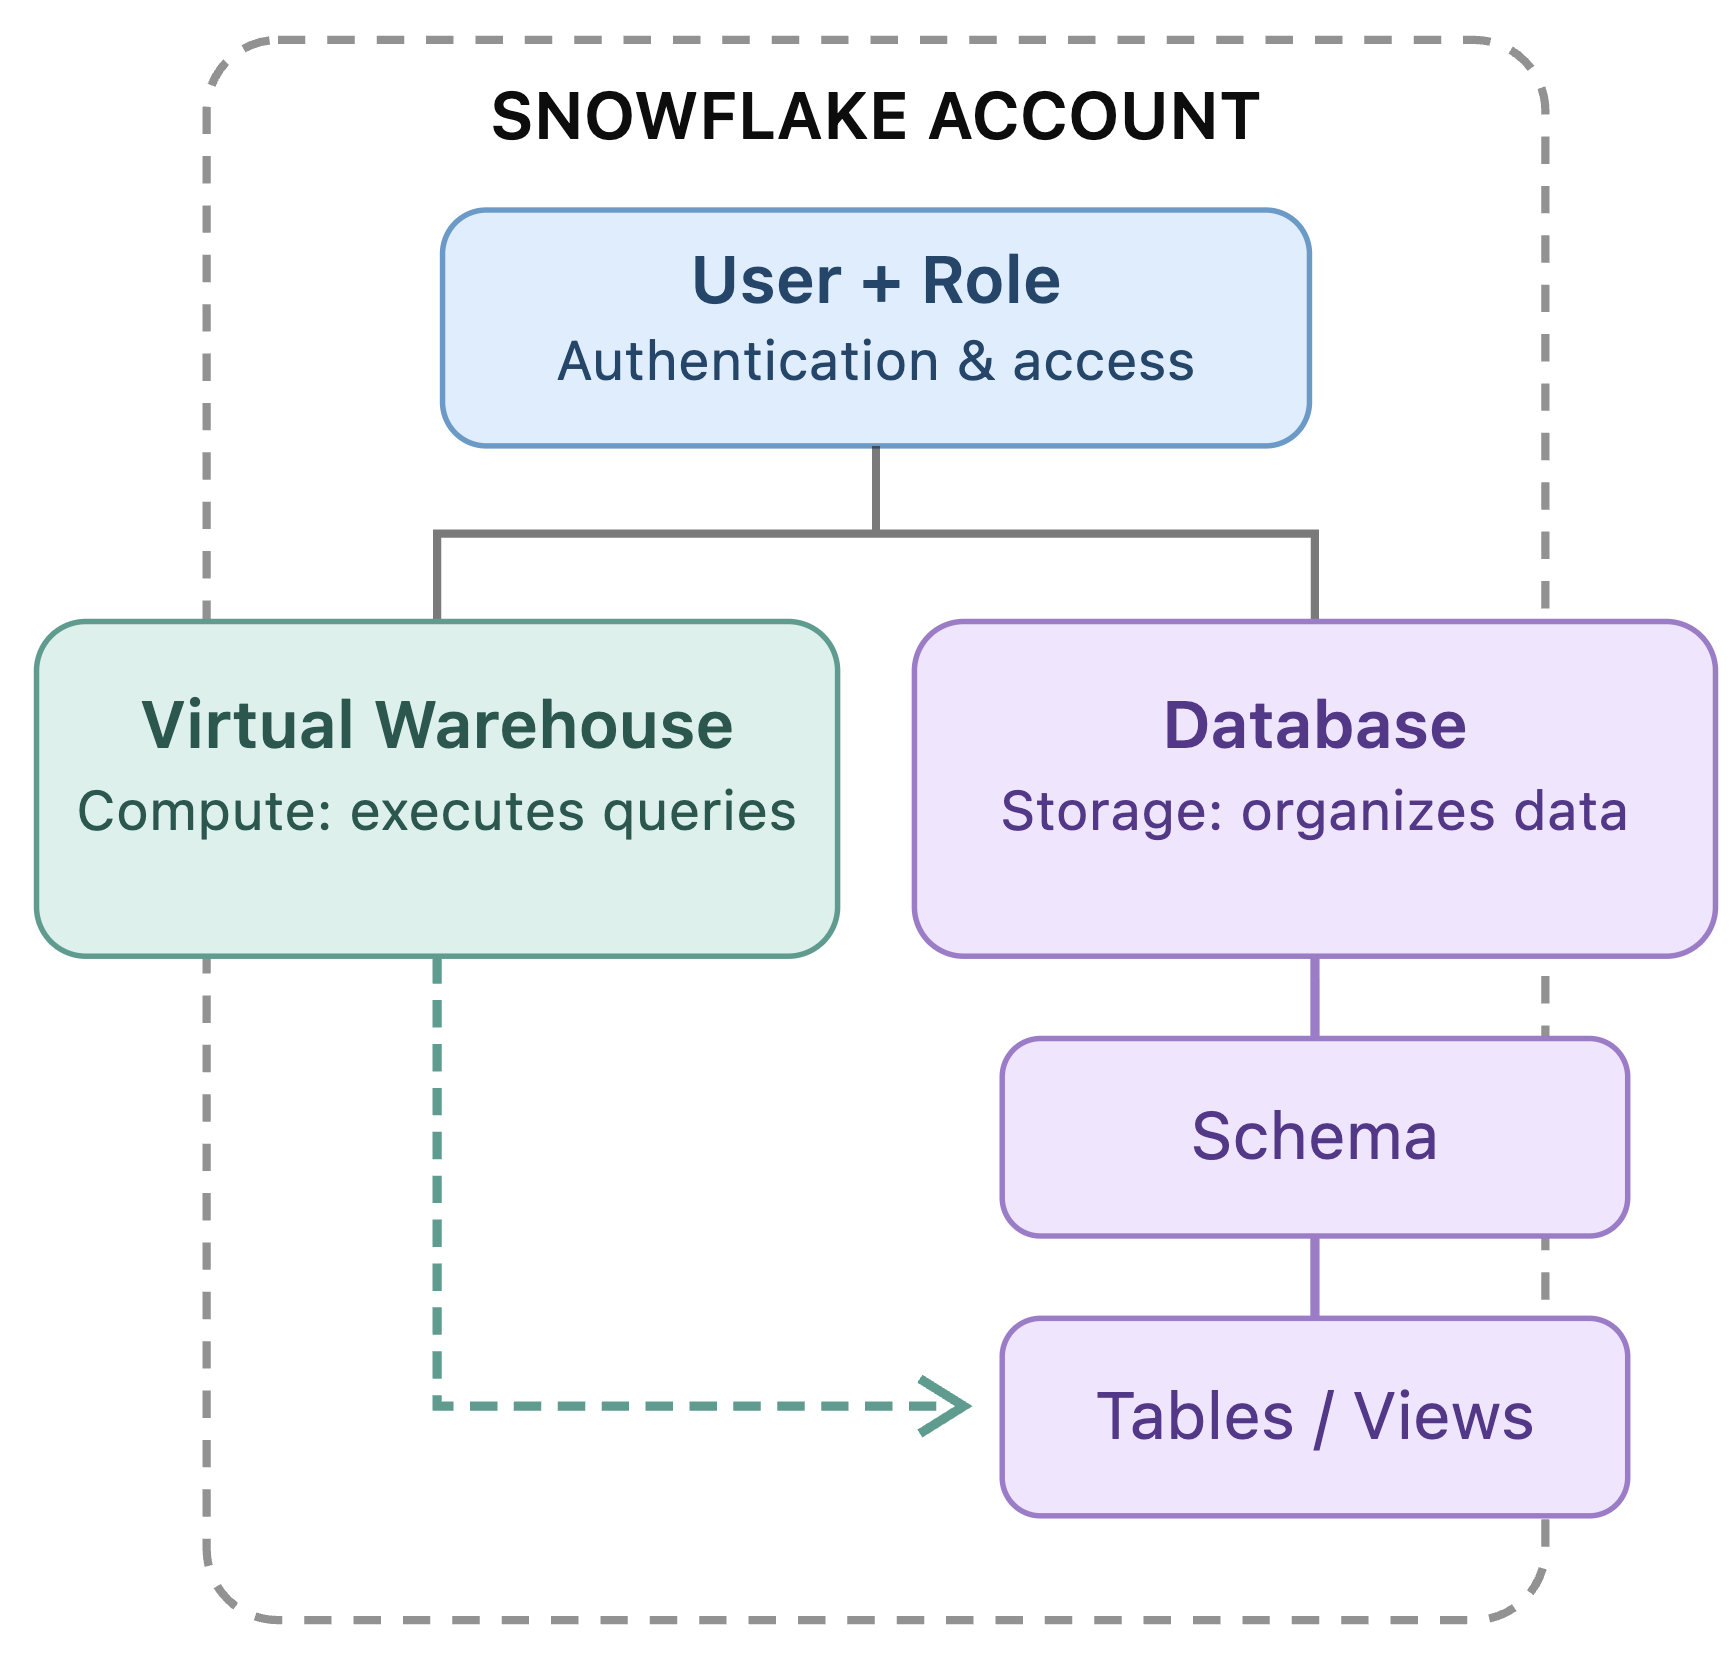

When connecting to Snowflake using the AI Connectors, you'll need to specify which resources to use and how to authenticate.

The following table maps each connector configuration parameter to its corresponding Snowflake concept.


| Configuration | Snowflake concept | Purpose |
|---|---|---|
| `account_identifier` | Account | Identifies the Snowflake account to connect to |
| `warehouse` | Virtual warehouse | Provides the compute resources for queries |
| `database_name` | Database | Specifies the default database |
| `schema_name` | Schema | Specifies the default schema |
| `username` | User | Identifies the connecting user |
| `pat` | Authentication | Authenticates the user using a Programmatic Access Token (PAT) |
| `role` | Account role | Determines the privileges activated for the session |

> **Note:** Snowflake supports multiple authentication methods, but you only need to configure **one** to establish a connection.
>
> In this cookbook, we'll use a **Programmatic Access Token (PAT)** because it's a straightforward way to authenticate without managing passwords or private keys. We'll walk through the entire process using PAT authentication, from configuring the connection to successfully exporting synthetic data.
>
> If you'd prefer to use another authentication method, don't worry! We've included a section later in this cookbook explaining how to configure RSA Key-Pair and OAuth 2.0 authentication.


# Finding Your Snowflake Connection Details

## Account Identifier

An account identifier uniquely identifies a Snowflake account and tells the connector which Snowflake environment to connect to.

Each Snowflake account can have its own users, virtual warehouses, databases, and security configuration.

Each account can have its own users, warehouses, databases, and security configuration.

Snowflake recommends using an account identifier in the following format:
```
<organization_name>-<account_name>
```

For example: `myorg-myaccount`

### Where to find your account identifier
You can find your account identifier directly in Snowflake's web interface, Snowsight.

1. Open Snowflake and sign in to your account.
2. Open the account selector, which displays your current Snowflake account.
3. Select View account details.
4. In the Account Details dialog, locate the account identifier or open the Connectors/Drivers tab to obtain the appropriate connection value.

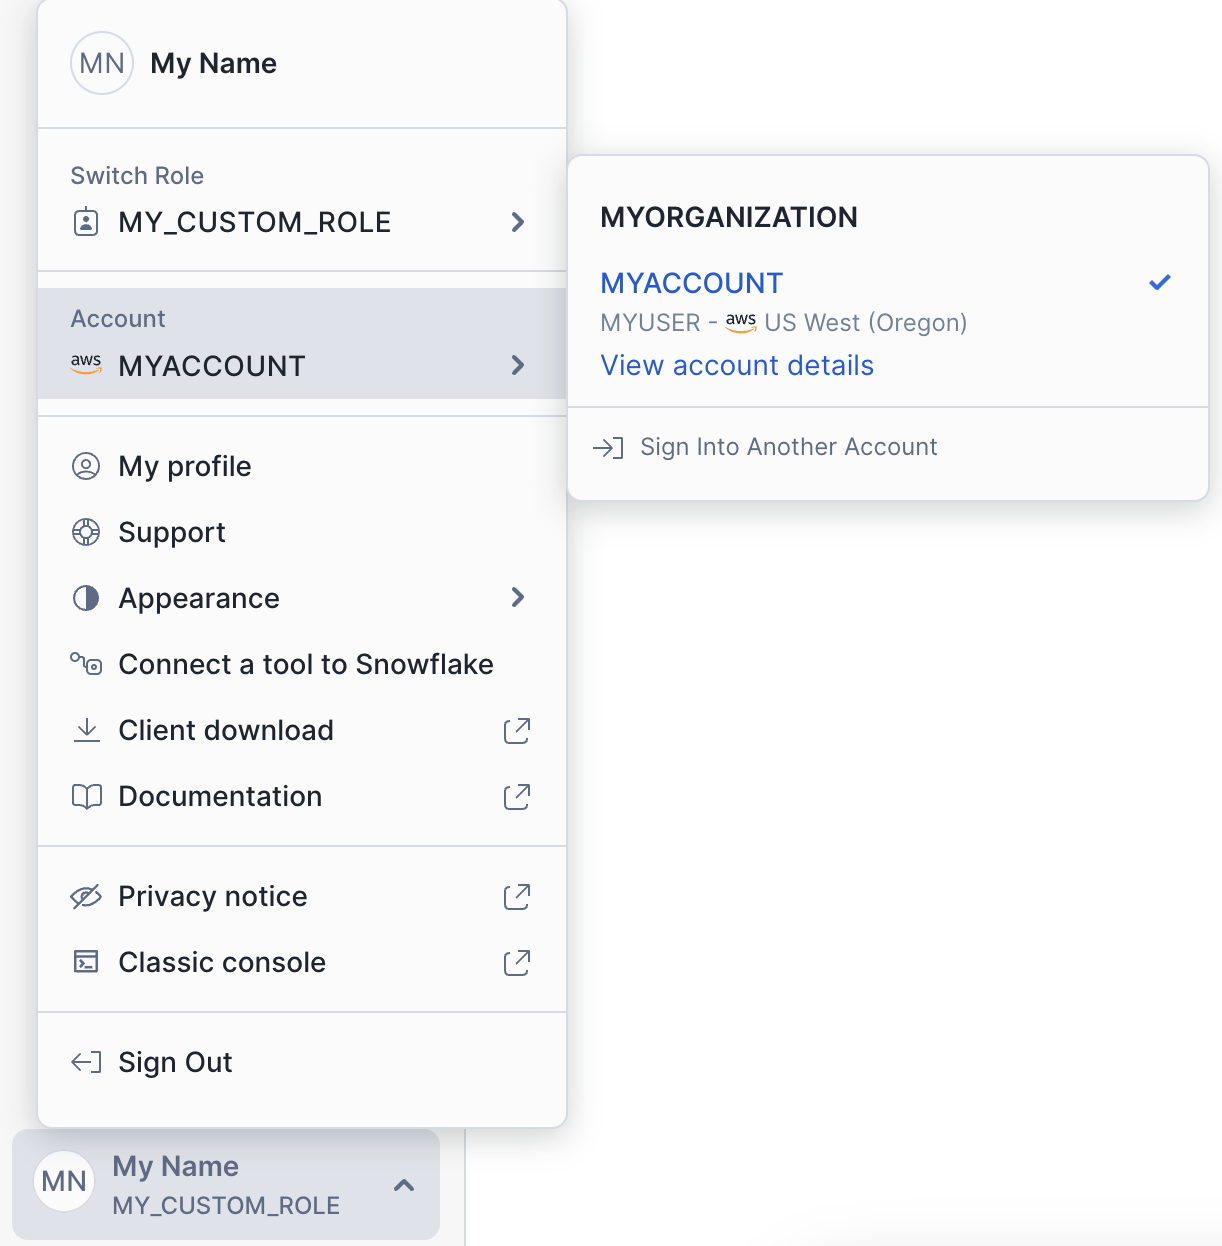

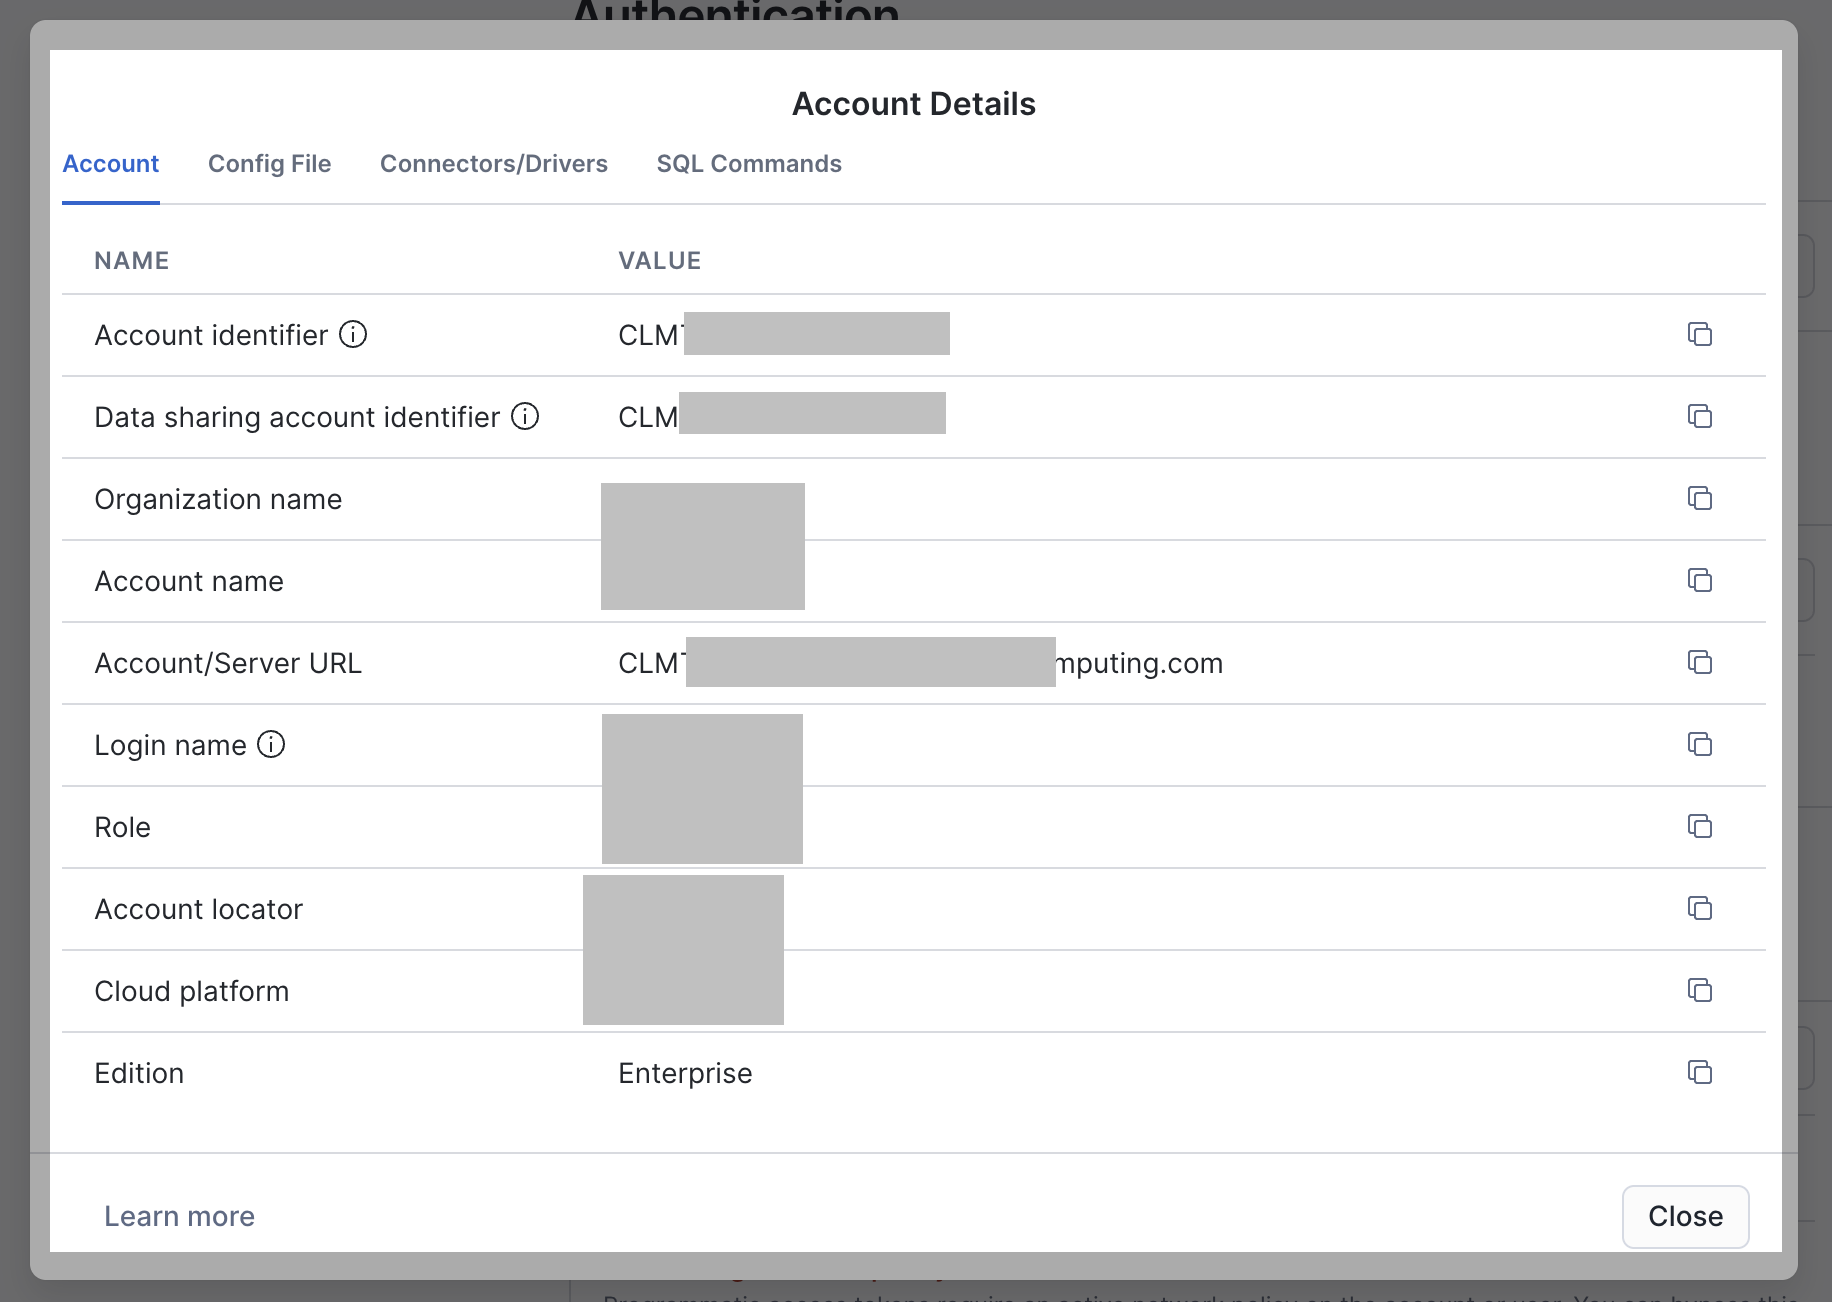

Once you've found your account identifier, add it to your YAML configuration file:

```yaml
options.SnowflakeConnector:
  account_identifier: myorg-myaccount
```

Alternatively you can run the following SQL query to retrieve your account identifier:
```sql
SELECT
    CURRENT_ORGANIZATION_NAME() AS ORGANIZATION_NAME,
    CURRENT_ACCOUNT_NAME() AS ACCOUNT_NAME,
    CURRENT_ORGANIZATION_NAME()
      || '-' ||
    CURRENT_ACCOUNT_NAME() AS ACCOUNT_IDENTIFIER;
```

The query returns your organization name, account name, and the combined account identifier. Copy the value from the `ACCOUNT_IDENTIFIER` column.

**Important**: Account identifiers are properties of Snowflake accounts. You do not create a new account identifier for each connection or user. The identifier already exists when the Snowflake account is provisioned.


## Warehouse

A virtual warehouse (often called simply a warehouse) is a collection of computing resources managed by Snowflake. It provides the processing power needed to execute SQL queries and perform data operations.

Warehouses are responsible for operations such as:

- Executing SQL queries.
- Inserting, updating, and deleting records.
- Loading and unloading data.
- Performing data transformations.

### Where to find an existing warehouse

You can find your available warehouses directly in Snowflake's web interface.

1. Sign in to your Snowflake account.
2. In the navigation menu, select Compute → Warehouses.
3. Locate the warehouse you want to use and copy its name.

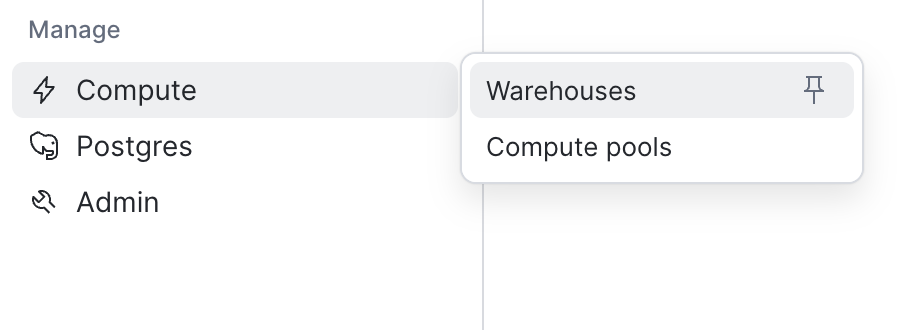

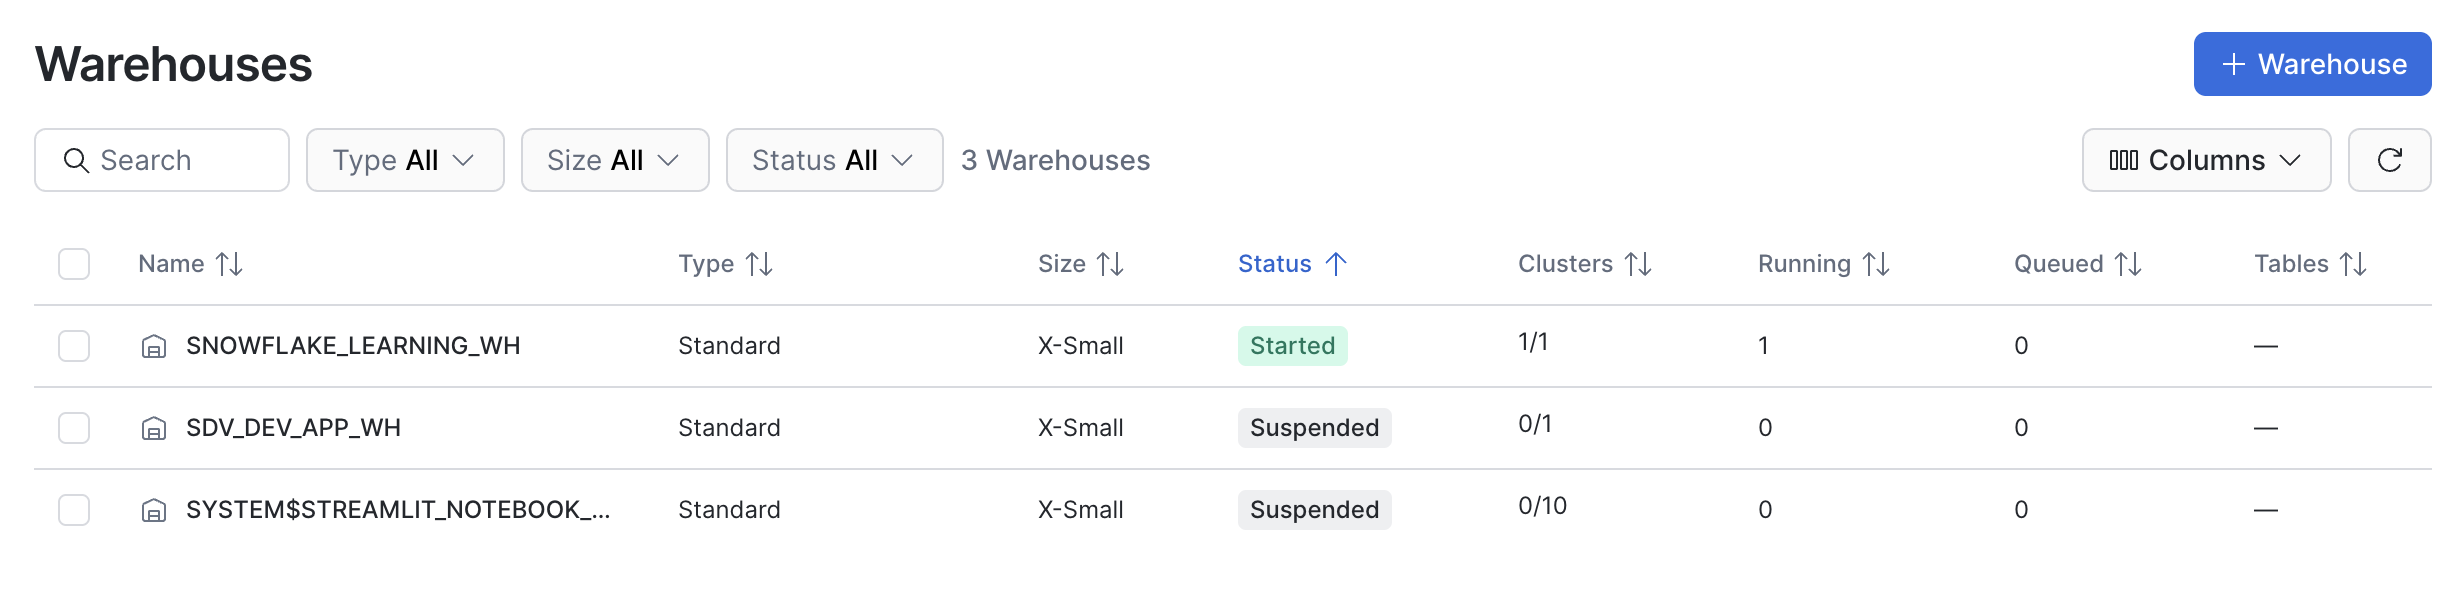

Alternatively, you can run the following SQL command in a Snowflake worksheet to list the warehouses available to your current role:

```sql
SHOW WAREHOUSES;
```

Once you've selected your warehouse, add its name to your YAML configuration file:
```yaml
options.SnowflakeConnector:
  warehouse: SNOWFLAKE_LEARNING_WH
```

We'll use this warehouse to execute queries when importing real data and exporting synthetic data.

## Authentication

To connect to Snowflake, you need to identify the user that will establish the connection and provide credentials to authenticate that user.

Snowflake supports several authentication methods, including passwords, Programmatic Access Tokens (PATs), RSA Key-Pair authentication, and OAuth 2.0.

For this cookbook, we'll use your existing Snowflake user and authenticate using a Programmatic Access Token (PAT).  We'll cover the other authentication methods and how to create a dedicated service user later in the cookbook.

### Finding Your Snowflake Username

Each Snowflake user has an identity associated with a Snowflake account. For the connector, you'll need the user's **Login Name**, which is the identifier Snowflake uses for authentication.

Snowflake distinguishes between the following user properties:

| Property | Description |
|---|---|
| User Name (`NAME`) | The internal identifier of the Snowflake user |
| Login Name (`LOGIN_NAME`) | The name used to authenticate to Snowflake |
| Email (`EMAIL`) | The email address associated with the user |

These values may be identical, but they can also be different. For the connector's `username` parameter, we'll need the `Login Name`.

#### Where to find your Login Name

You can find your Login Name directly in Snowflake:

1. Sign in to your Snowflake account.
2. In the navigation menu, select Governance & security → Users & roles.
3. Under Users, locate and select your current Snowflake user.
4. Find the Login Name property and copy its value.

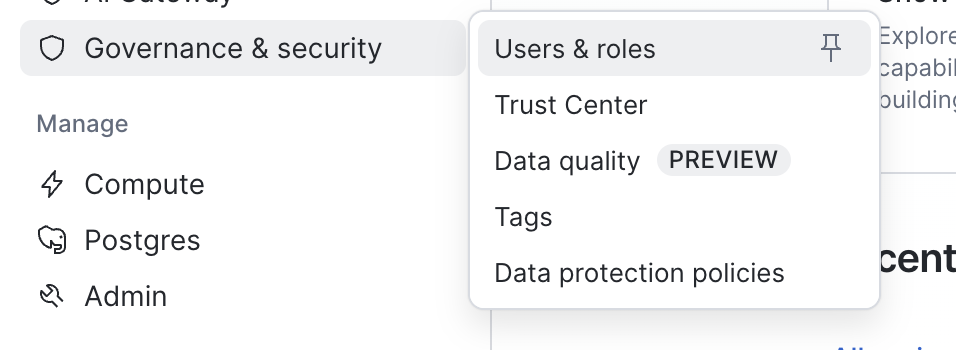

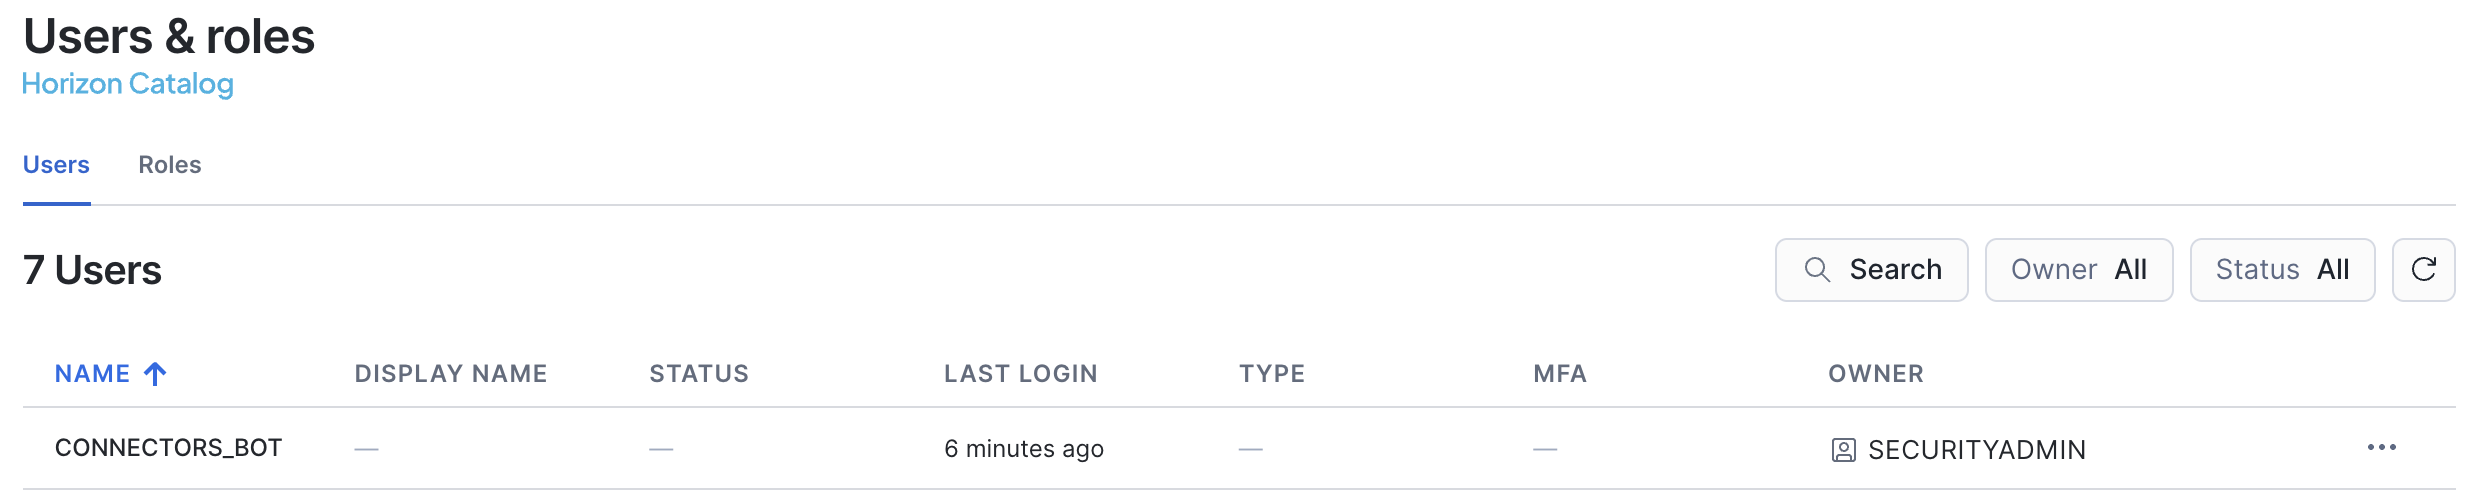

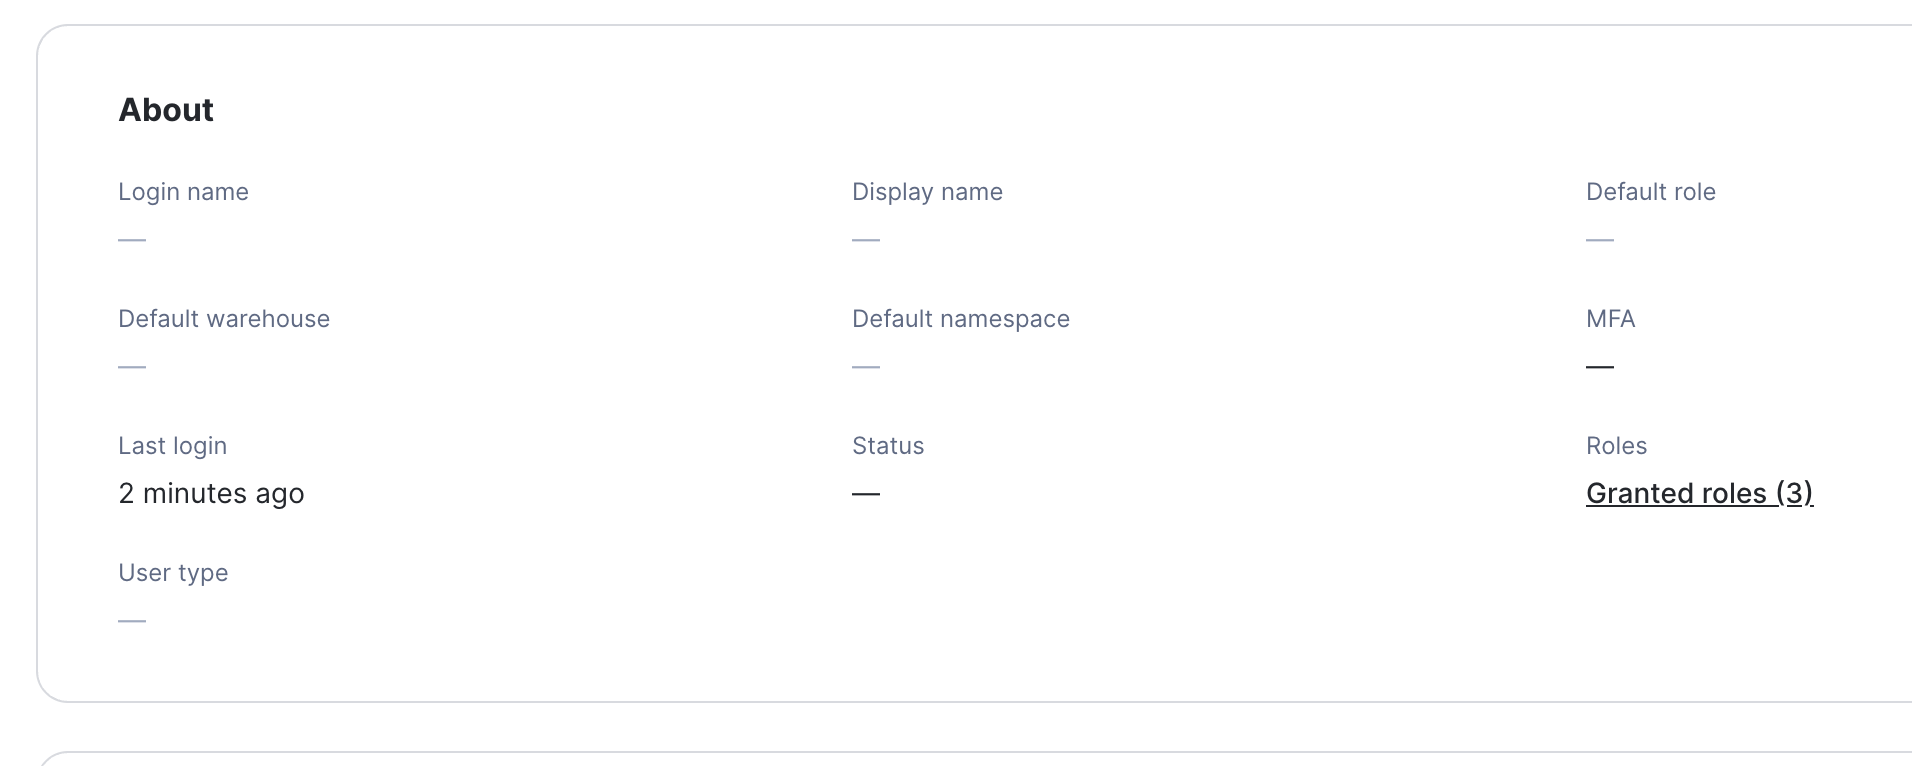


Once you've obtained your Login Name, add it to your YAML configuration file:

```yaml
auth:
  username: CONNECTORS_BOT
```

We'll use this username when configuring PAT authentication in the following section.

### Creating a Programmatic Access Token (PAT)

Now that you've identified your Snowflake username, you'll need a way to authenticate your connection.

For this cookbook, we'll use a Programmatic Access Token (PAT). A PAT is a Snowflake-generated token that allows applications to authenticate without using your account password.

We'll create a PAT for your existing Snowflake user. Later in this cookbook, we'll explain how to create a dedicated service user for production integrations.

#### Where to generate a PAT

You can generate a PAT directly from Snowflake's web interface, Snowsight.

1. Sign in to your Snowflake account.
2. Navigate to Governance & security → Users & roles.
3. Select your Snowflake user.
4. Under Programmatic access tokens, select Generate new token.
5. Configure the token:
   - Name: Enter a descriptive name, such as `AI_CONNECTORS_PAT`.
   - Comment: Optionally, describe what the token will be used for.
   - Expires in: Select how long the token should remain valid.
   - Role restriction: Select One specific role (recommended) and choose a role with the permissions needed to access your data.
6. Select Generate.
7. Copy or download your generated token and store it securely.

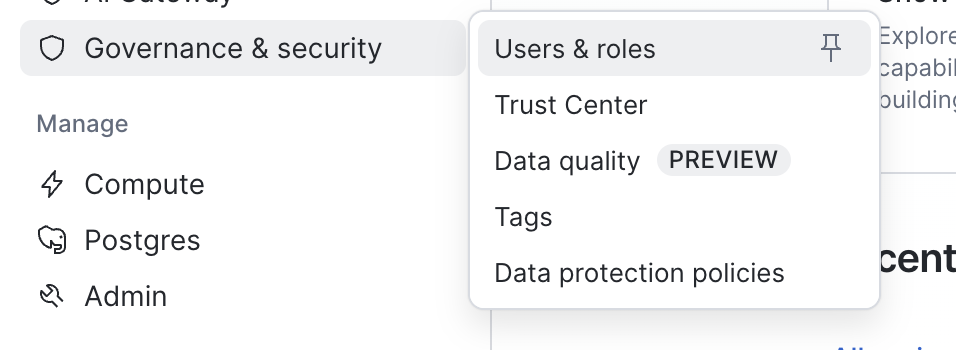

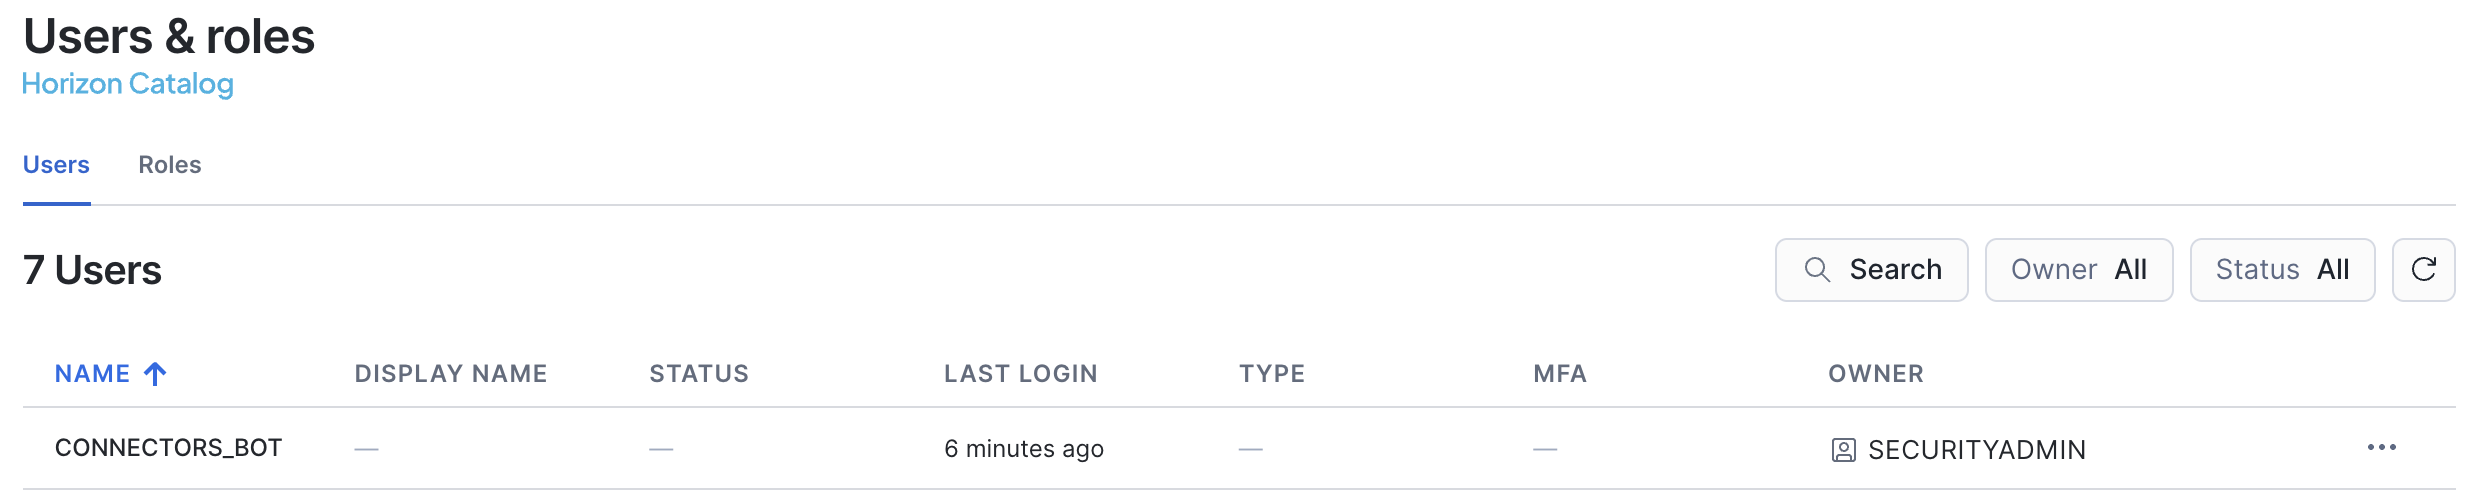

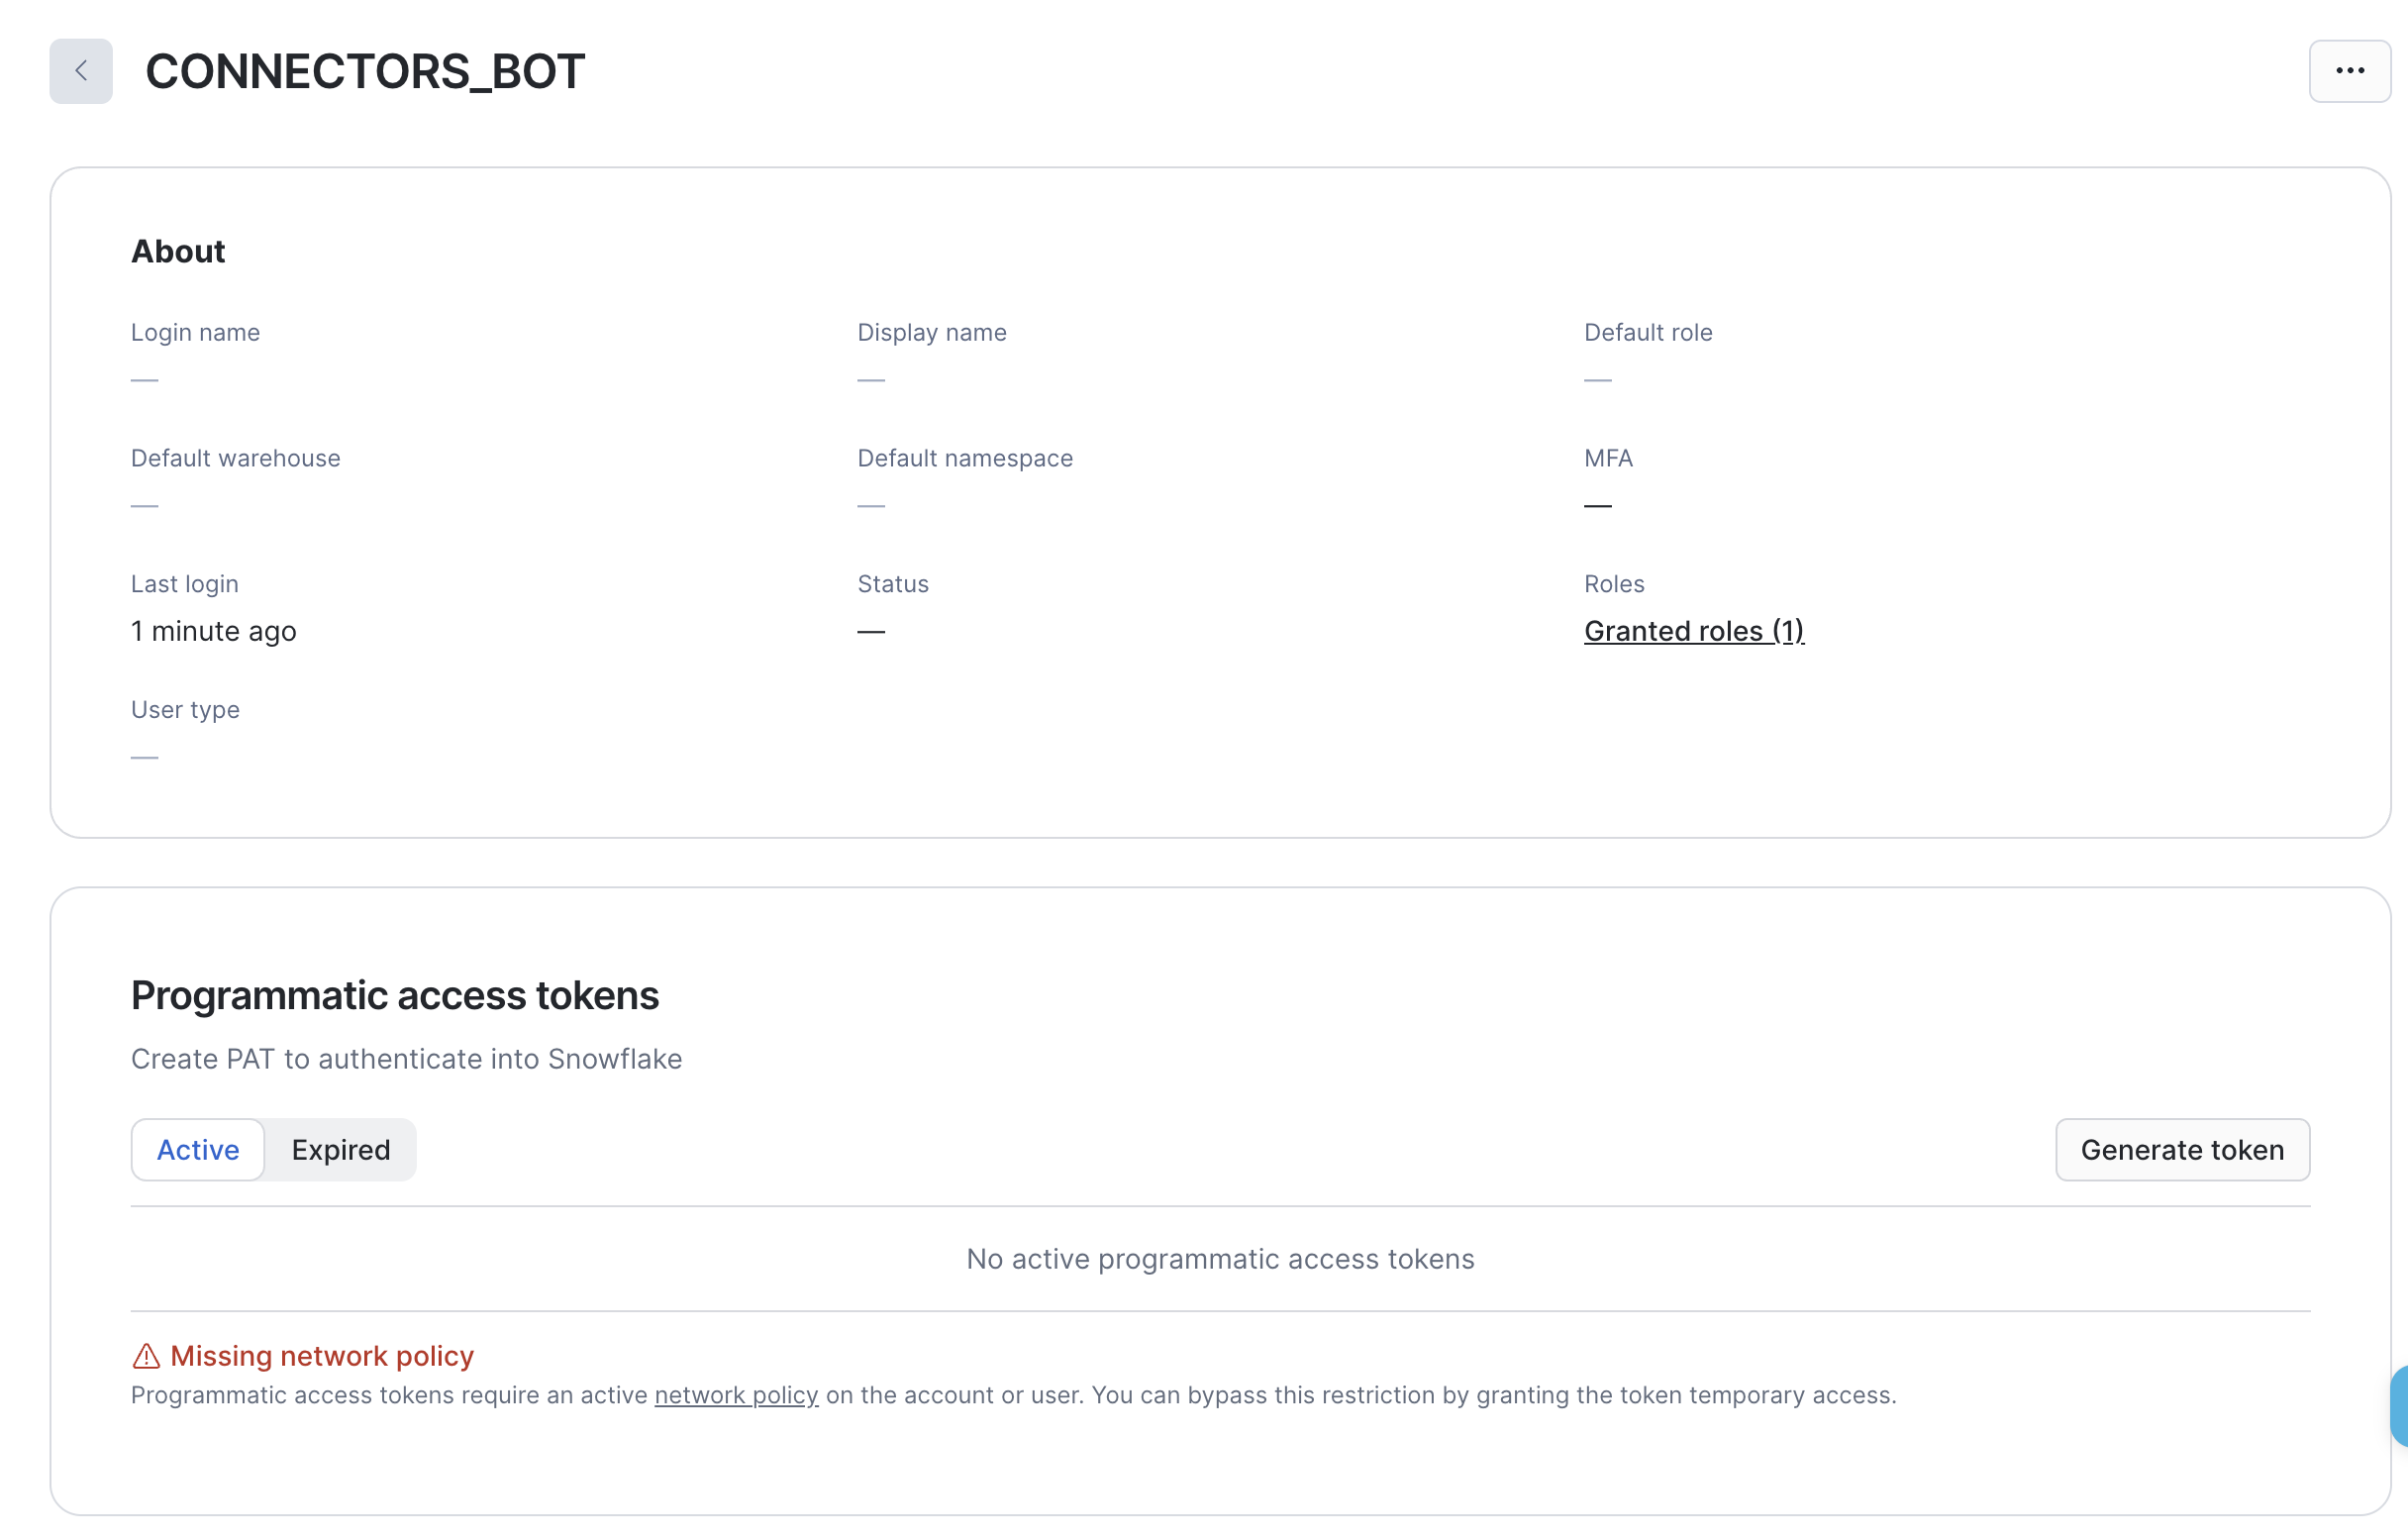

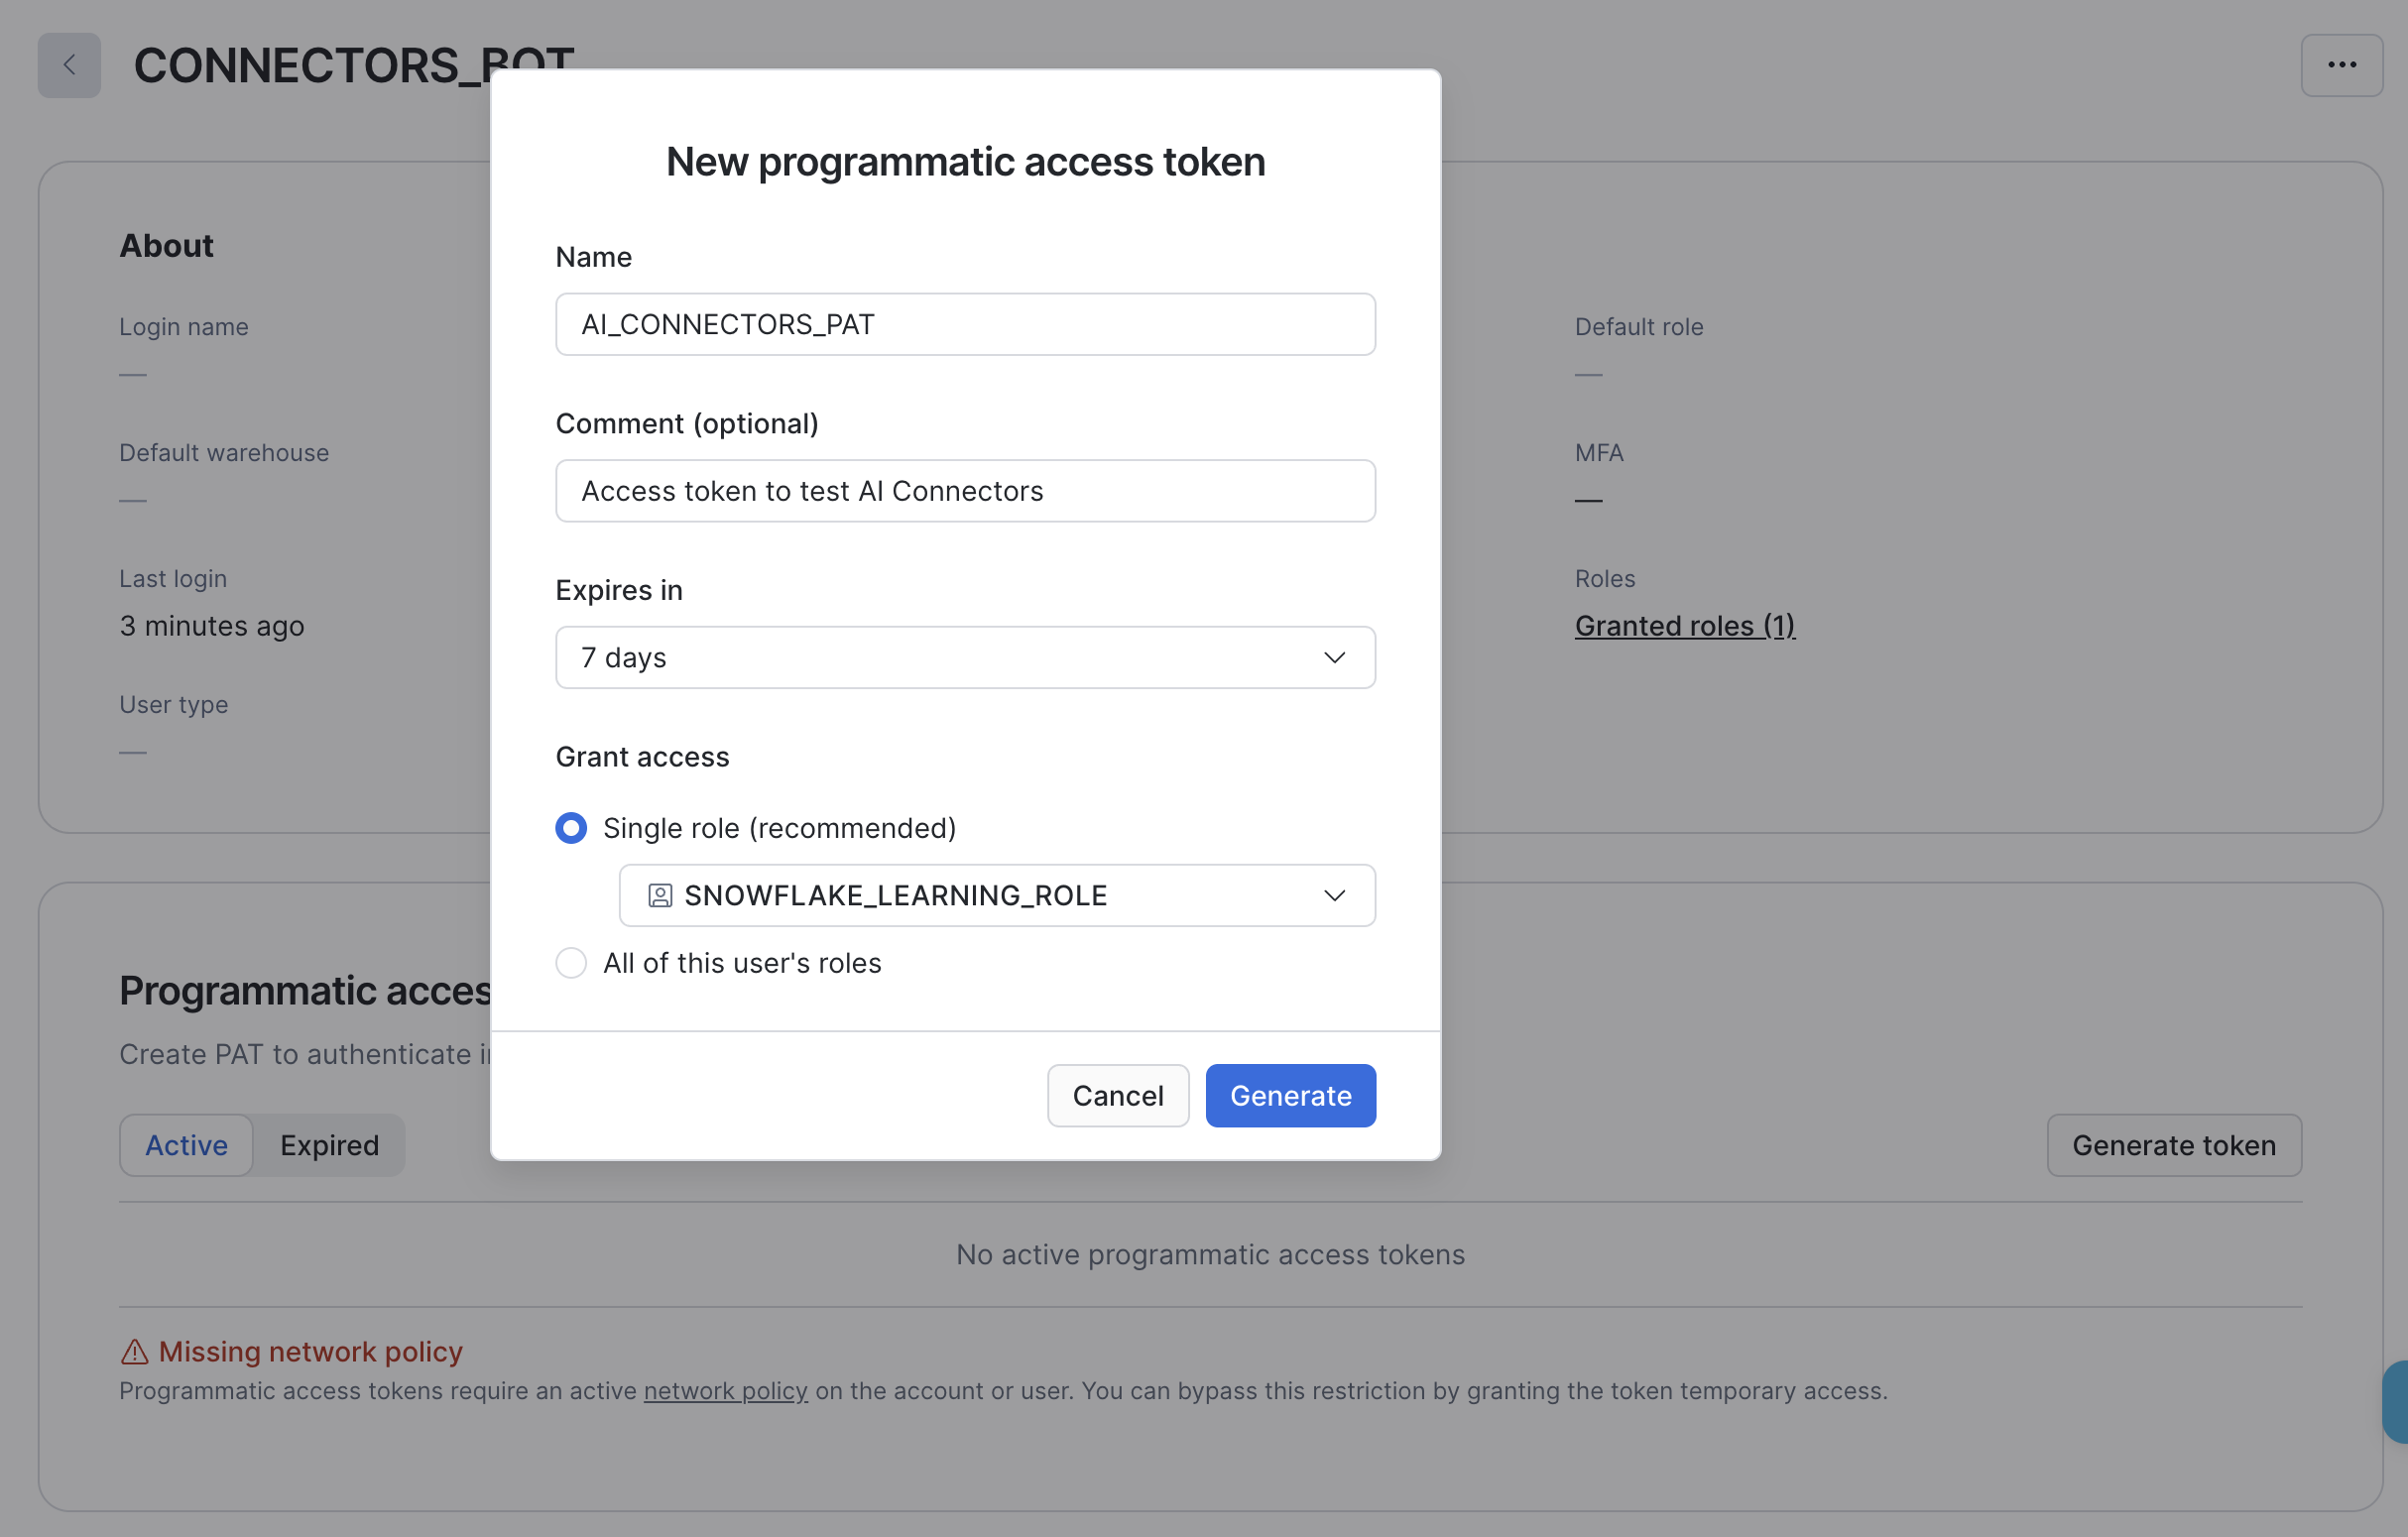

Once the token is generated, if you see a warning about `Missing network policy`, in order to be able to use it you would have to clik on the three dots and `Bypass the network policy` for a certain amount of time:


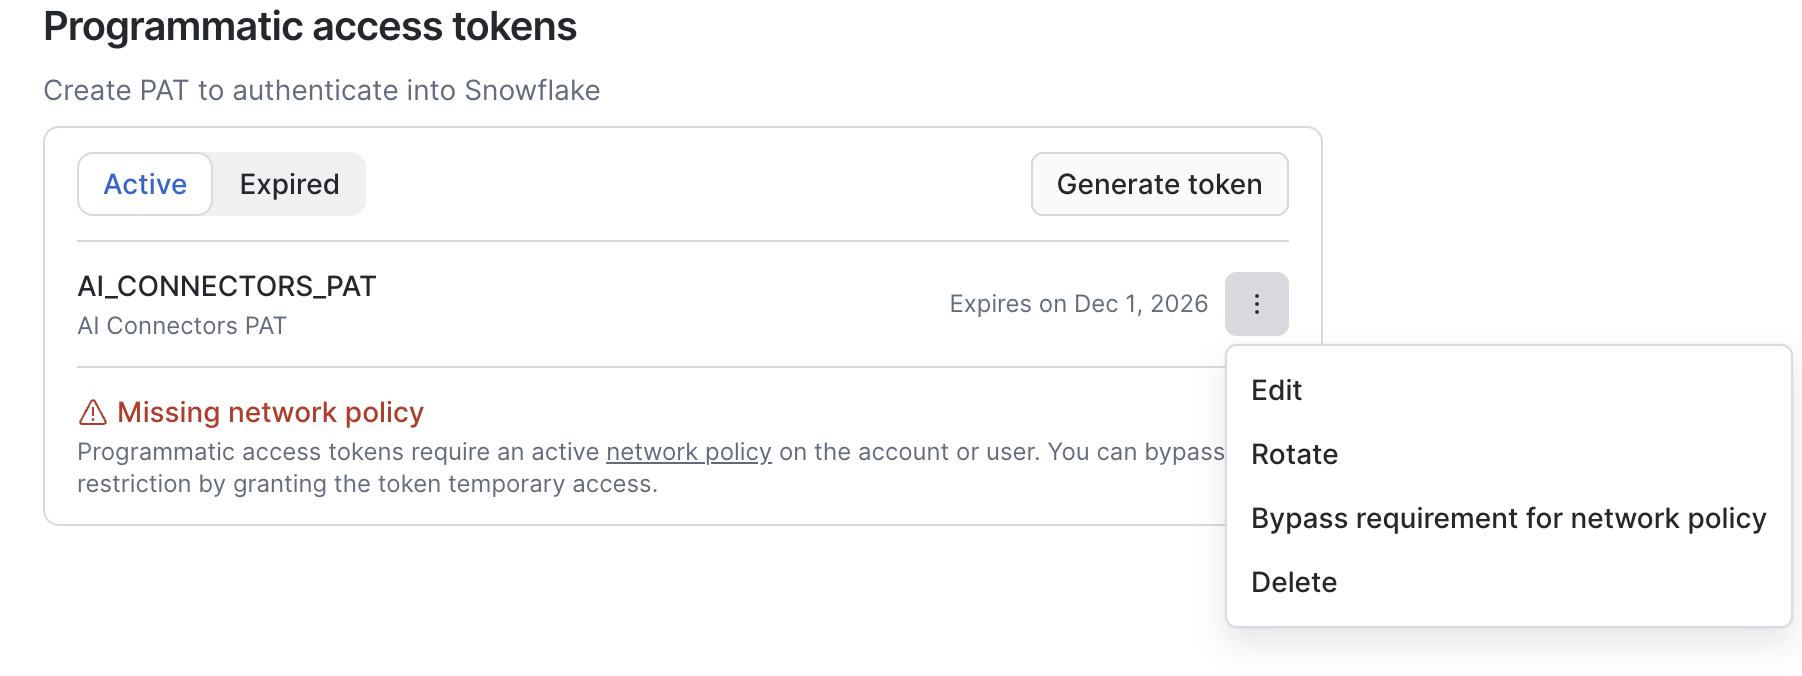

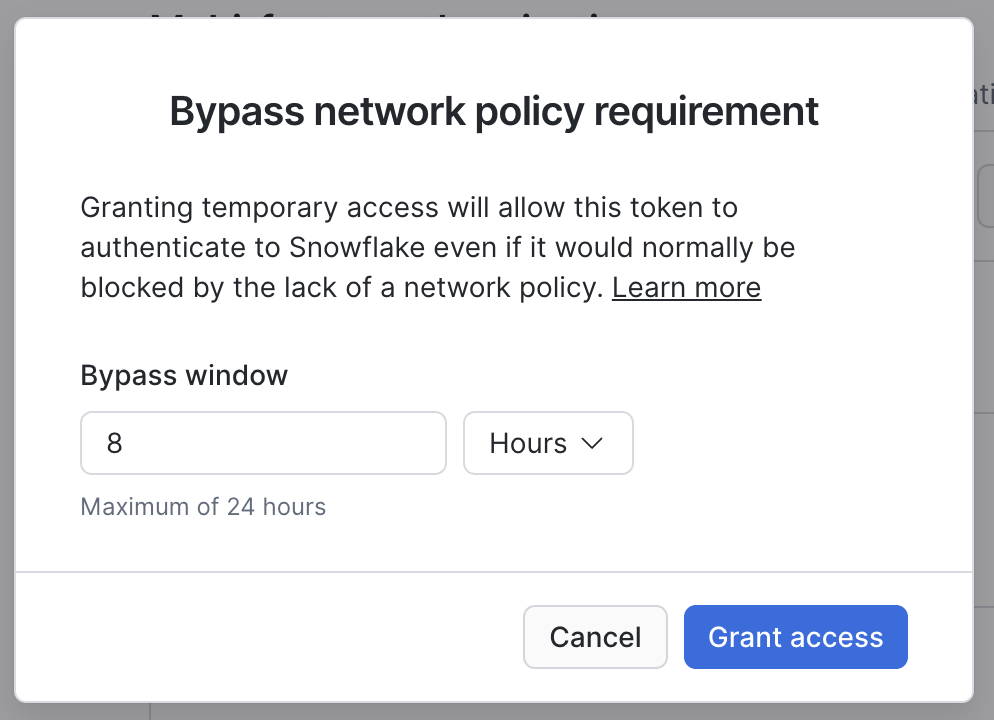

For more information, see the [Snowflake Programmatic Access Tokens documentation](https://docs.snowflake.com/en/user-guide/programmatic-access-tokens).

### Adding your PAT to the configuration

Once you've generated your PAT, add it to your YAML configuration file under `options.SnowflakeConnector`:

```yaml
auth:
  username: CONNECTORS_BOT
  password: ''

options.SnowflakeConnector:
  pat: '<your_programmatic_access_token>'
```

When using PAT authentication, you don't need to provide a password. The connector will use the PAT to authenticate your Snowflake user.

We'll use this token along with the other connection details gathered in the previous sections to establish our connection to Snowflake.

# Connecting to Snowflake

Now that we've gathered our Snowflake connection details and created a Programmatic Access Token (PAT), we're ready to connect to our database.

In this example, we'll use the `SnowflakeConnector` to:

1. Import real data from an existing Snowflake schema.
2. Generate synthetic data using the SDV `HSASynthesizer`.
3. Export the synthetic data to a separate schema in Snowflake.

We'll use the following Snowflake resources throughout this example:

| Resource | Value |
|---|---|
| Database | `SNOWFLAKE_CONNECTOR_TEST` |
| Source schema | `rel-hm` |
| Destination schema | `rel-hm_synthetic` |
| Authentication | Programmatic Access Token (PAT) |

Both schemas belong to the same Snowflake database. However, we'll use separate configuration files for importing and exporting so that the source data remains separate from the generated synthetic data.

## Exploring the Source Data

Before connecting, let's take a look at the dataset we'll be working with.

In Snowflake's web interface, Snowsight:

1. Navigate to **Catalog → Database Explorer**.
2. Select the `SNOWFLAKE_CONNECTOR_TEST` database.
3. Open the `rel-hm` schema.
4. Explore the tables available in the schema.



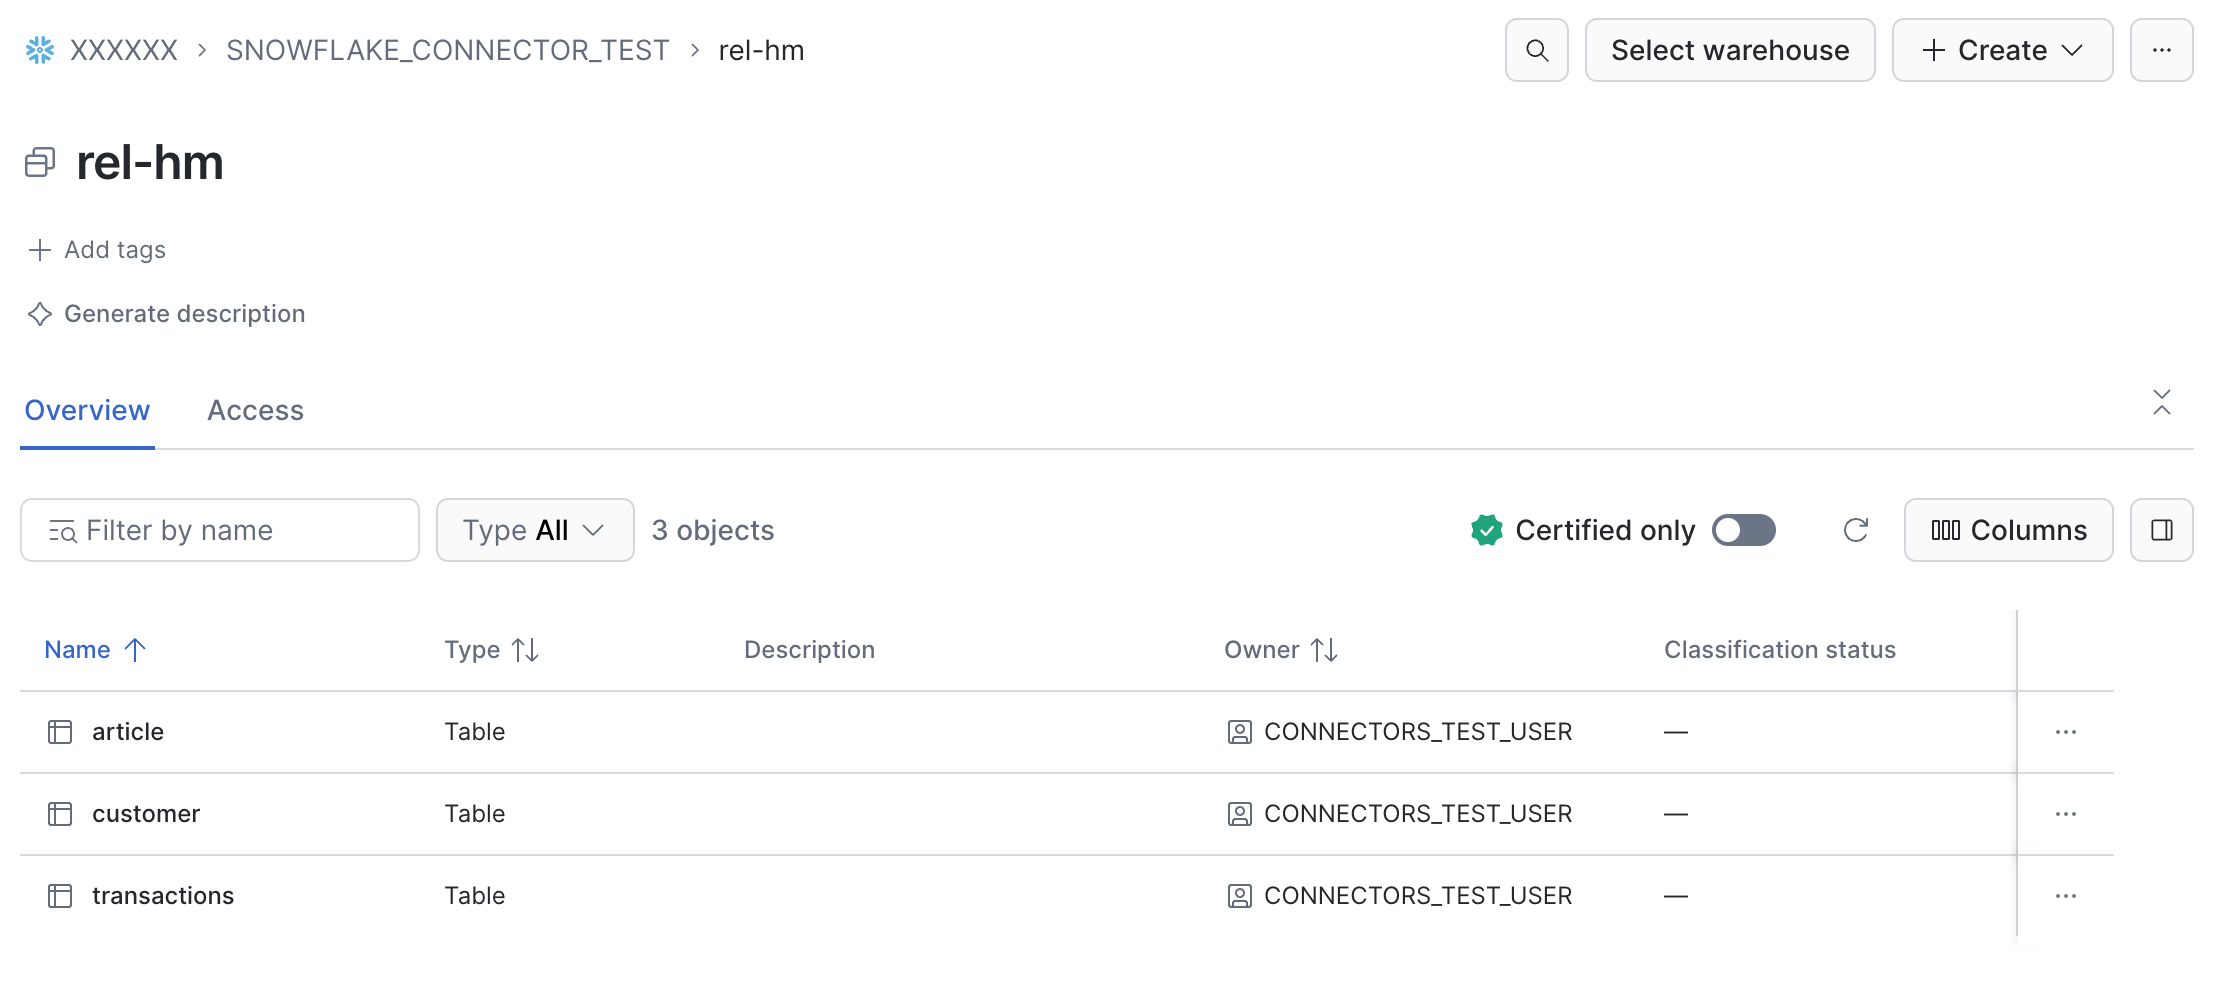

This is the dataset we'll import into Python using the `SnowflakeConnector`.

## Creating the Configuration Files

To connect to Snowflake, we'll create two YAML configuration files:

- `snowflake_import_config.yaml`: Specifies where the real data will be imported from.
- `snowflake_export_config.yaml`: Specifies where the synthetic data will be exported.

Both files use the same YAML structure, but reference different schemas.

### Import Configuration

Create a file named `snowflake_import_config.yaml` in the same directory as your notebook.

```yaml
connection:
  database_name: SNOWFLAKE_CONNECTOR_TEST
  schema_name: rel-hm

auth:
  username: CONNECTORS_BOT
  password: ''

runtime:
  connection_timeout: 300

options.SnowflakeConnector:
  account_identifier: myorg-myaccount
  warehouse: SNOWFLAKE_LEARNING_WH
  role: CONNECTORS_TEST_USER
  pat: your_programmatic_access_token
```

Replace the example values with the account identifier, username, warehouse, role, and PAT obtained in the previous sections.

The `connection` section specifies the database and schema containing our real data.

Because we're using PAT authentication, we leave `auth.password` empty and provide our token under `options.SnowflakeConnector.pat`.

**Important:** The configured role must have the appropriate permissions to read tables from the source schema. At minimum, this typically includes `USAGE` on the warehouse, database, and schema, and `SELECT` on the tables. For more information, see the [Snowflake Access Control documentation](https://docs.snowflake.com/en/user-guide/security-access-control-overview).

### Export Configuration

Next, create a second file named `snowflake_export_config.yaml`.

This file will contain nearly identical connection details, but we'll change the `schema_name` to point to our destination schema.

```yaml id="dqs35v"
connection:
  database_name: SNOWFLAKE_CONNECTOR_TEST
  schema_name: rel-hm_synthetic

auth:
  username: CONNECTORS_BOT
  password: ''

runtime:
  connection_timeout: 300

options.SnowflakeConnector:
  account_identifier: myorg-myaccount
  warehouse: SNOWFLAKE_LEARNING_WH
  role: CONNECTORS_TEST_USER
  pat: your_programmatic_access_token
```

Notice that the only difference between our two example configurations is the `schema_name`.

The import configuration points to `rel-hm`, while the export configuration points to `rel-hm_synthetic`.

**Important:** The role used for exporting must have the necessary privileges to create the destination schema and tables, or write to existing objects, depending on the export operation.

We'll use this configuration later when exporting our synthetic data.

## Importing Data from Snowflake

With our import configuration ready, we can start working with the `SnowflakeConnector`.

### Initialize the Connector

First, import the connector and create an instance:


In [4]:
from sdv.io.database import SnowflakeConnector

connector = SnowflakeConnector()

Next, load the import configuration:

In [5]:
connector.set_import_config(
    filepath='snowflake_import_config.yaml'
)

The connector will use the information in our YAML file to establish a connection to the Snowflake database.

### Create Metadata

The connector can automatically create SDV metadata by inspecting the tables in the configured Snowflake schema.

In [6]:
metadata = connector.create_metadata()

By default, this creates metadata for all the tables in our source schema, including their columns, data types, and inferred primary-key and foreign-key relationships.

You can inspect the generated metadata:

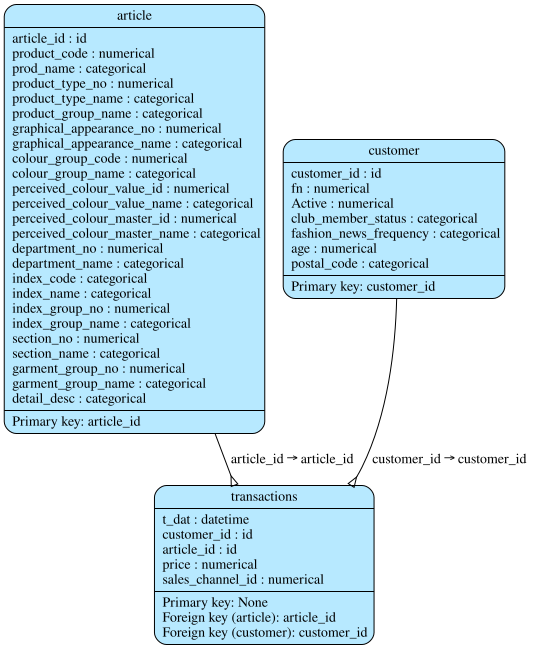

In [7]:
metadata.visualize()

**Important:** Automatically inferred metadata may not always be accurate. We recommend reviewing it before generating synthetic data, especially the relationships between tables.

For more information, see the [SDV Metadata documentation](https://docs.sdv.dev/sdv/concepts/metadata).

### Import Real Data

Now that we have our metadata, we can import a subset of the real data from Snowflake.


In [8]:
real_data = connector.import_random_subset(metadata=metadata)

Downloaded 2500 rows from: rel-hm.article
Downloaded 337009 rows from: rel-hm.transactions
Downloaded 213942 rows from: rel-hm.customer


The connector automatically selects a subset of the data based on the inferred metadata.

The imported data is returned as a Python dictionary, where each key represents a table name and each value contains a pandas DataFrame.

To see which tables were imported and how many rows they contain, run:


In [9]:
for table_name, table in real_data.items():
    print(f'{table_name}: {len(table)} rows')

article: 2500 rows
transactions: 337009 rows
customer: 213942 rows


At this point, we've successfully imported real data from Snowflake into Python.

## Generating Synthetic Data

Now that we have our real data and metadata, we can use SDV to generate synthetic data.

For this example, we'll use the `HSASynthesizer`, a multi-table synthesizer that learns patterns and relationships from the imported data.

### Train the Synthesizer

First, import and initialize the synthesizer with our metadata:

In [10]:
from sdv.multi_table import HSASynthesizer

grm = HSASynthesizer(metadata)

Next, train it using the real data we imported from Snowflake:

In [11]:
grm.fit(real_data)

During training, the synthesizer learns patterns from the real dataset and the relationships between its tables.

### Generate Synthetic Data

Once training is complete, we can generate synthetic data:

In [12]:
synthetic_data = grm.sample_scale(1)

The `sample_scale(1)` method generates synthetic data at approximately the same scale as the training data.

Like our imported data, the generated synthetic data is stored as a dictionary of pandas DataFrames.

We can inspect the number of rows generated for each table:

In [13]:
for table_name, table in synthetic_data.items():
    print(f'synthetic {table_name}: {len(table)} synthetic rows')

synthetic article: 2500 synthetic rows
synthetic customer: 213942 synthetic rows
synthetic transactions: 337009 synthetic rows


We've now generated our synthetic dataset! The next step is to export it back to Snowflake.

## Exporting Synthetic Data to Snowflake

We'll now export our generated synthetic data to the `rel-hm_synthetic` schema in the `SNOWFLAKE_CONNECTOR_TEST` database.

This allows us to keep our real and synthetic datasets separate while maintaining them within the same Snowflake account.

### Set the Export Configuration

We'll reuse the same connector instance that we used for importing.

Load the export configuration file:

In [14]:
connector.set_export_config(
    filepath='snowflake_export_config.yaml'
)

Notice that we're using `set_export_config` instead of `set_import_config`.

This tells the connector where to write the synthetic data.

### Export Synthetic Data

Now we can export our synthetic dataset:

In [15]:
connector.export(
    synthetic_data,
    mode='write'
)

Created schema: rel-hm_synthetic
Exporting data to schema 'rel-hm_synthetic'...
Writing table: 'article' with 2500 rows, 25 columns
Writing table: 'customer' with 213942 rows, 7 columns
Writing table: 'transactions' with 337009 rows, 5 columns


The `write` mode creates new destination objects and writes the synthetic data to them. If the destination data already exists, this mode will raise an error rather than replacing it.

**Important:** Make sure the destination schema does not contain conflicting tables from a previous export. Other export modes, such as `append` and `overwrite`, are available for working with existing data.

For more information, see the [AI Connectors Usage API](https://docs.sdv.dev/sdv/integration/db/api).

### Verify the Export in Snowflake

Once the export is complete, return to Snowsight to verify the results.

1. Navigate to **Catalog → Database Explorer**.
2. Open the `SNOWFLAKE_CONNECTOR_TEST` database.
3. Locate the `rel-hm_synthetic` schema.
4. Explore the newly created tables.

You should see the tables containing the synthetic data generated by SDV.

You can also query individual tables to inspect their contents.


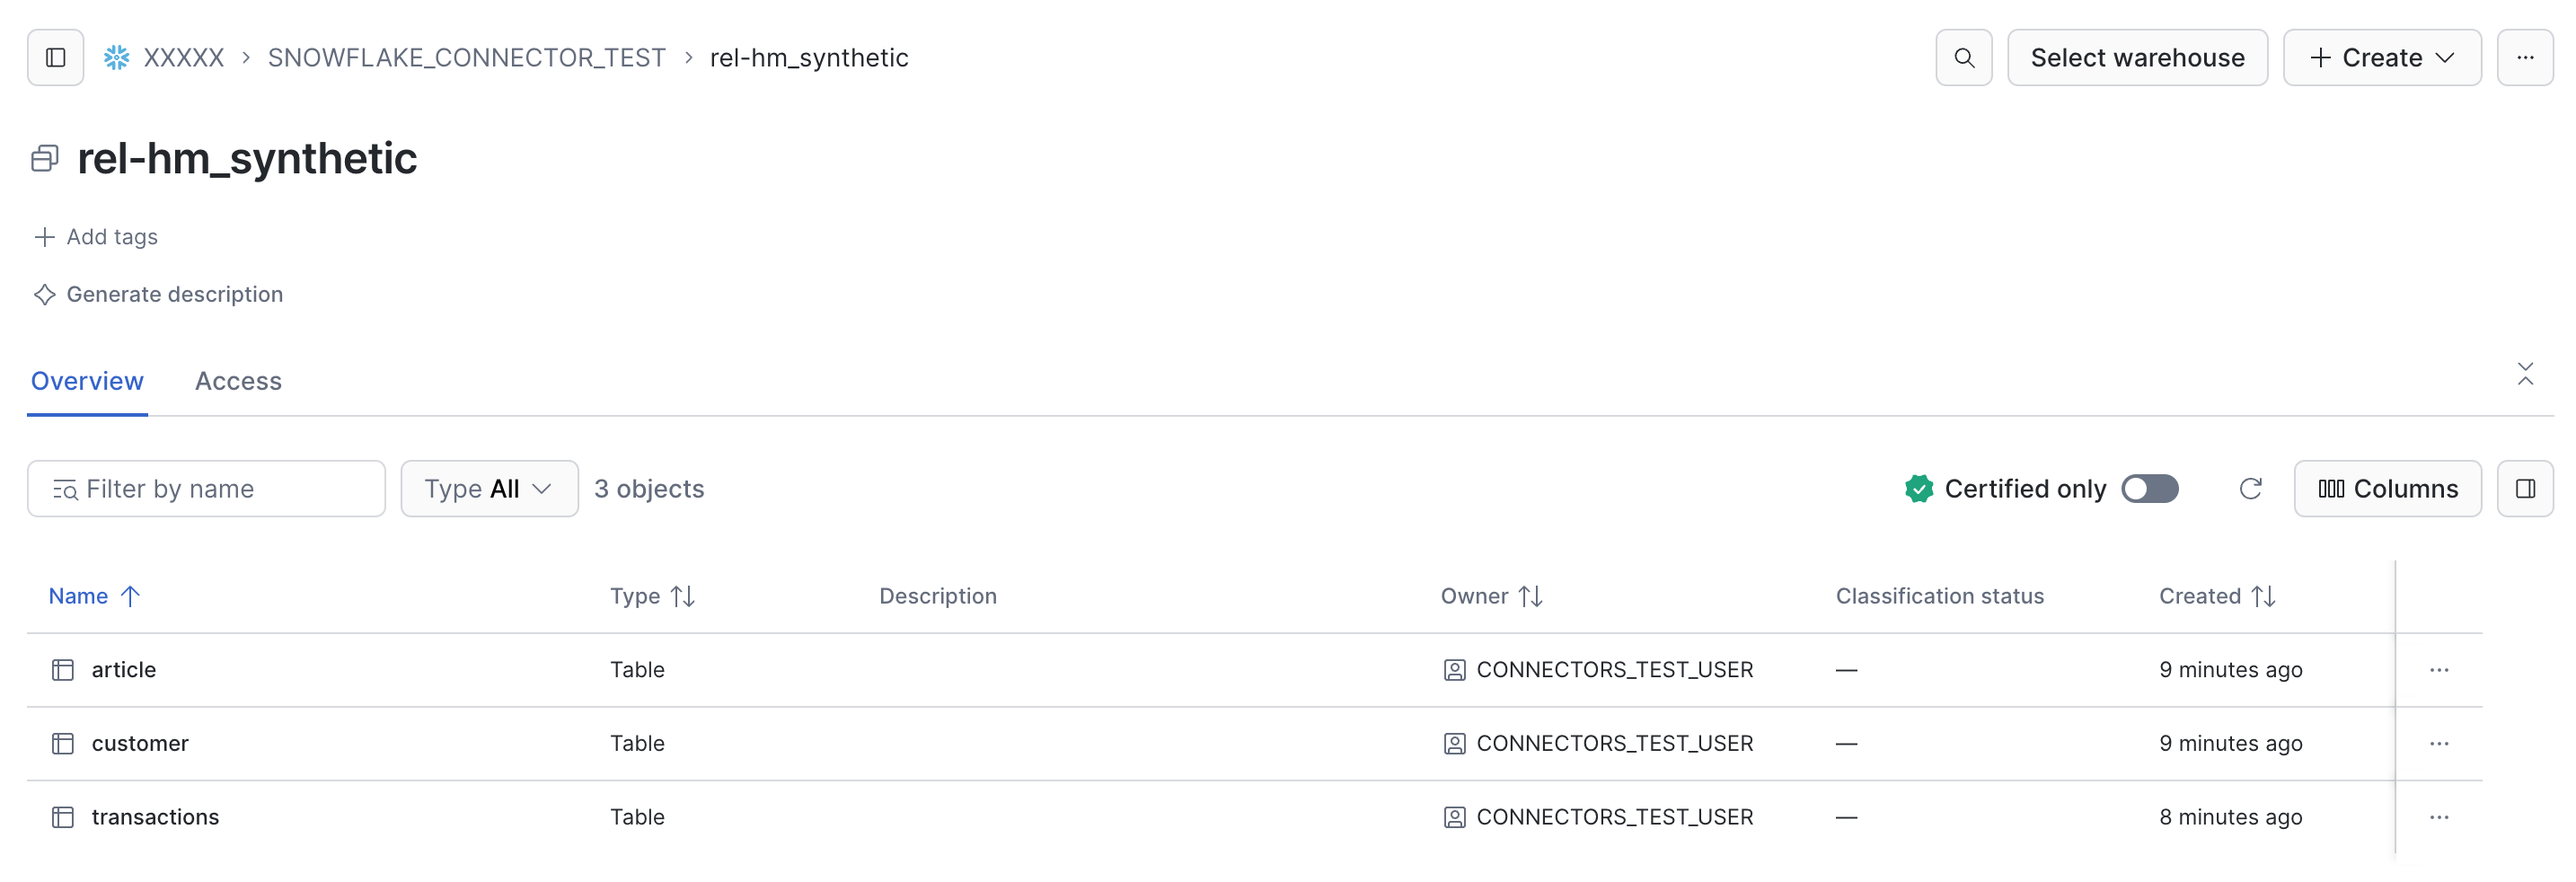

To verify that our synthetic data has been successfully exported to Snowflake, we can run the following SQL queries. Make sure to adjust the database and schema names to match your configuration.

First we can check the number of rows in each exported table:
```sql
SELECT
    table_name,
    row_count
FROM SNOWFLAKE_CONNECTOR_TEST.INFORMATION_SCHEMA.TABLES
WHERE table_schema = 'rel-hm_synthetic'
  AND table_type = 'BASE TABLE'
ORDER BY table_name;
```


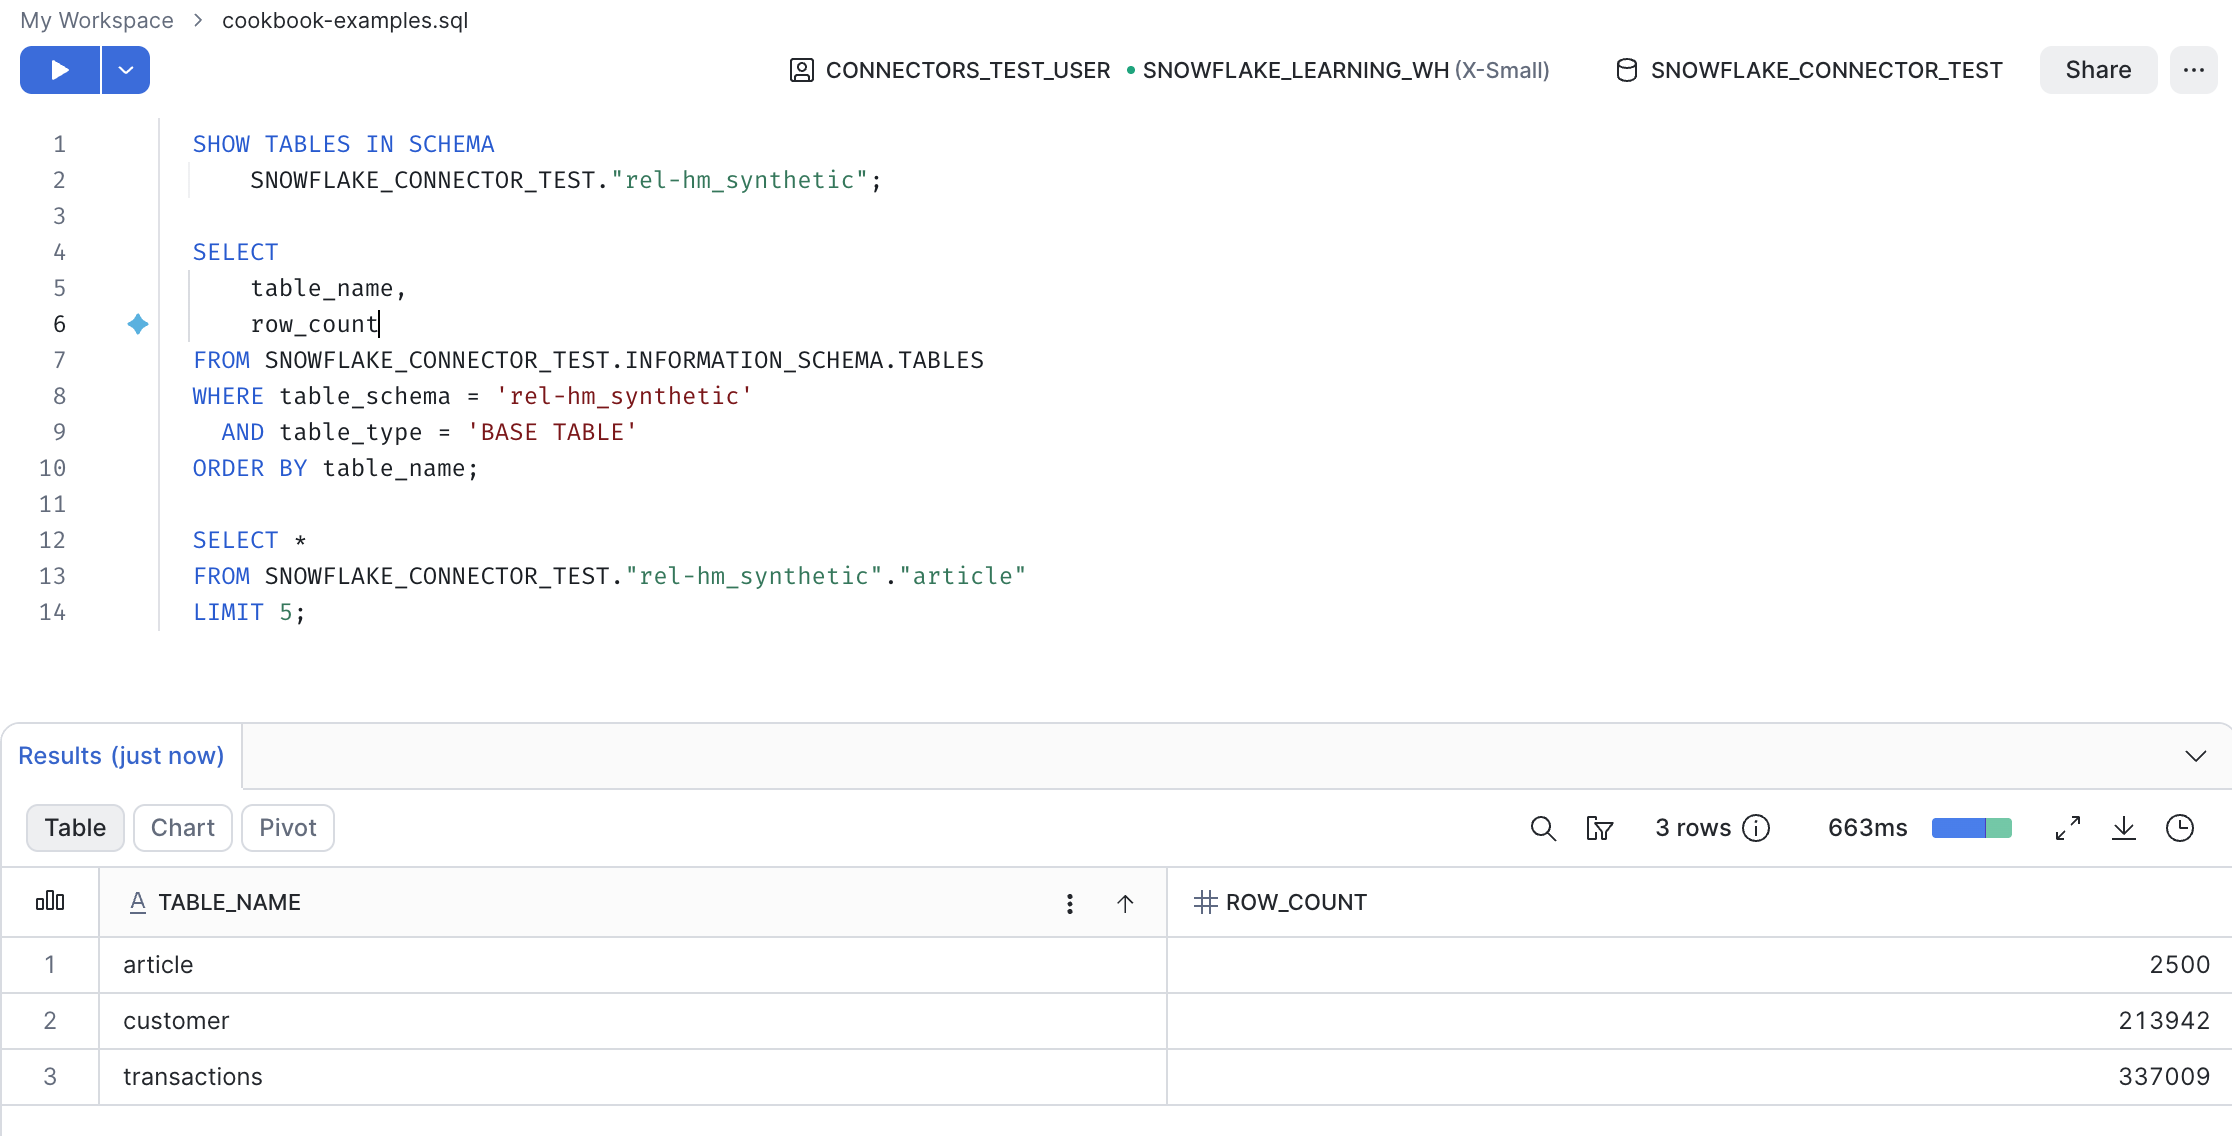

Finally, we can compare the records stored in Snowflake with the synthetic data generated in our notebook.
For example, let's retrieve five records from the exported articles table:
```sql
SELECT *
FROM SNOWFLAKE_CONNECTOR_TEST."rel-hm_synthetic"."articles"
LIMIT 5;
```

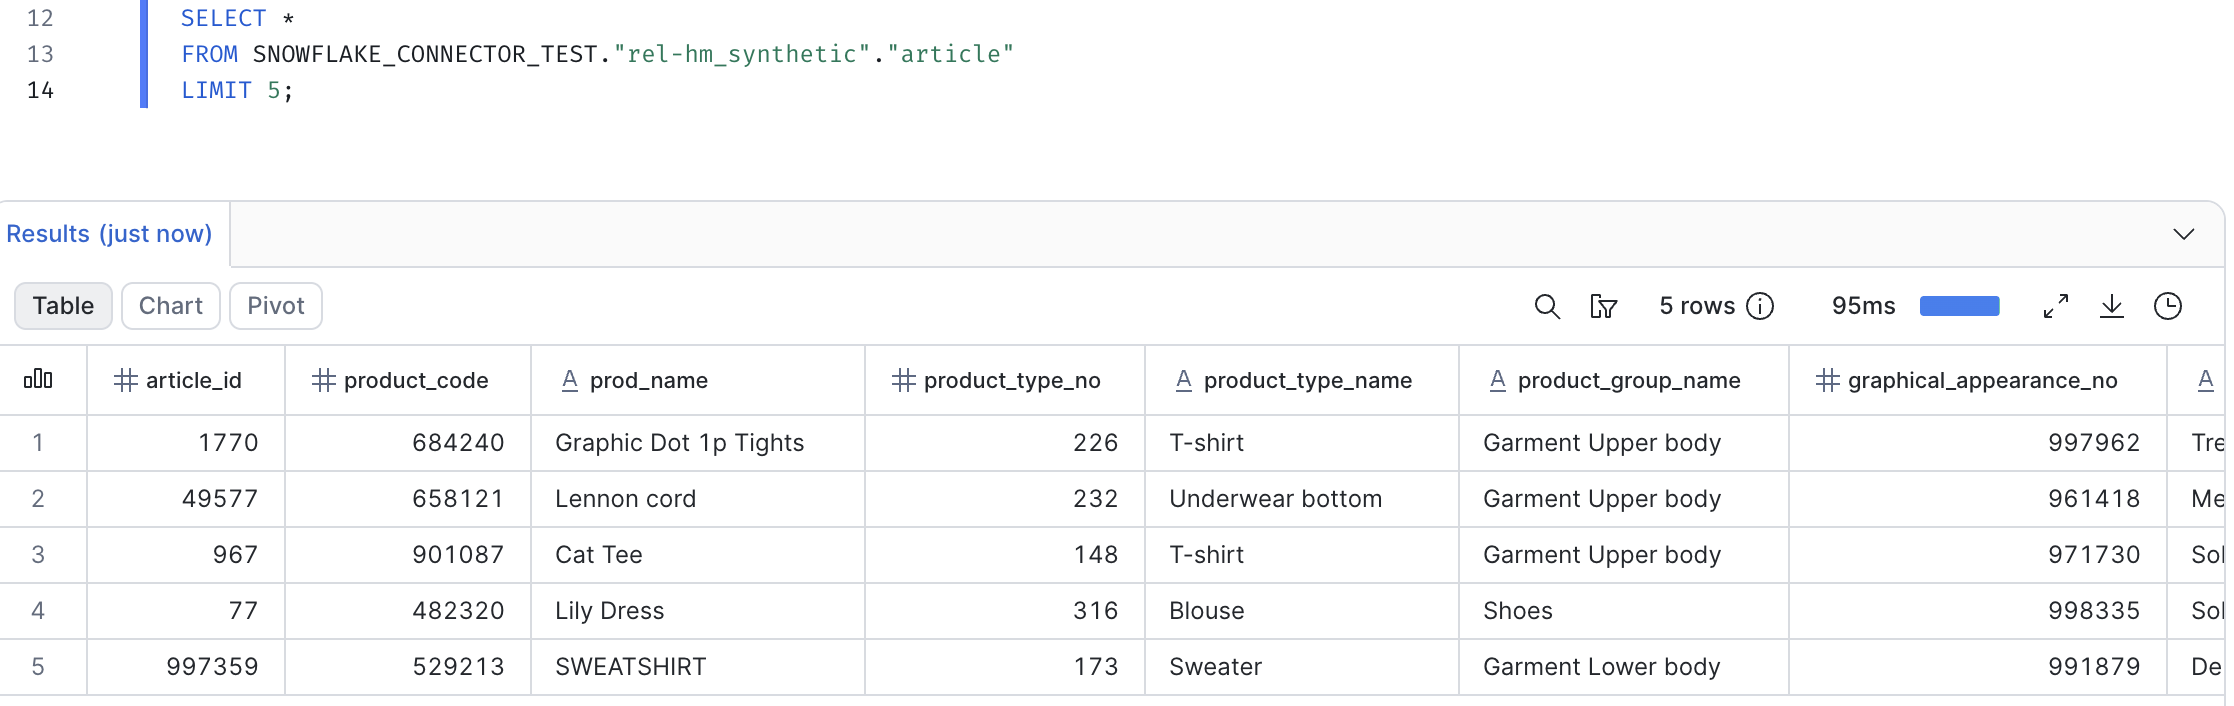

In [17]:
synthetic_data['article'].head(5)

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,1770,684240,Graphic Dot 1p Tights,226,T-shirt,Garment Upper body,997962,Treatment,14,Light Yellow,...,Projects Dresses,A,Ladieswear,3,Ladieswear,21,Kids Outerwear,1007,Knitwear,"Waist belt in imitation leather with a square,..."
1,49577,658121,Lennon cord,232,Underwear bottom,Garment Upper body,961418,Melange,42,Black,...,Kids Dress-up/Football,H,Children Sizes 92-140,7,Baby/Children,60,Womens Jackets,1006,Jersey Fancy,Relaxed-fit top in sweatshirt fabric made from...
2,967,901087,Cat Tee,148,T-shirt,Garment Upper body,971730,Solid,65,Dark Blue,...,Jersey Fancy,G,Divided,2,Ladieswear,54,Divided Collection,1004,Shoes,Fitted top in soft velour with a yoke and slee...
3,77,482320,Lily Dress,316,Blouse,Shoes,998335,Solid,71,Black,...,Shirt,A,Ladieswear,4,Ladieswear,43,Divided Collection,1005,Jersey Basic,Cardigan in a soft jacquard knit with dropped ...
4,997359,529213,SWEATSHIRT,173,Sweater,Garment Lower body,991879,Denim,91,Black,...,Jersey,H,"Children Accessories, Swimwear",6,Divided,33,Womens Tailoring,1005,Jersey Fancy,5-pocket jeans in washed stretch denim with ha...


## Conclusion

Congratulations! You've successfully completed an end-to-end workflow using the `SnowflakeConnector`.

Throughout this cookbook, you've learned how to:

1. Configure a Snowflake connection using PAT authentication.
2. Import metadata and real data from an existing Snowflake schema.
3. Train an SDV `HSASynthesizer` and generate synthetic data.
4. Export the synthetic data into a separate Snowflake schema.
5. Verify the exported tables directly in Snowflake.

In the following sections, we'll explore additional authentication methods and how to set up a dedicated service user for production integrations.

# Advanced Configuration: Service Users and Authentication Methods

So far, we've used our existing Snowflake user and a Programmatic Access Token (PAT) to connect to Snowflake, import real data, and export synthetic data.

While this approach works well for getting started, we recommend using a dedicated service user for production integrations. This allows you to manage permissions, credentials, and access independently of an individual account.

In this section, we'll cover how to create a service user, configure its permissions, and use the additional authentication methods supported by the `SnowflakeConnector`.

## Creating a Dedicated Service User

Snowflake supports a user type called `SERVICE`, designed for applications and automated integrations that interact with Snowflake without human intervention.

Unlike personal users, `SERVICE` users cannot authenticate using passwords. Instead, they use programmatic authentication methods such as PATs, RSA key pairs, or OAuth.

### Create the Service User

To create a new user, you'll need the `USERADMIN` role or another role with the `CREATE USER` privilege. If you don't have the required permissions, ask your Snowflake administrator to perform this step.

For this example, we'll create a service user named `AI_CONNECTORS_BOT`.

Open a Snowflake worksheet and run:

```sql
USE ROLE USERADMIN;

CREATE USER IF NOT EXISTS AI_CONNECTORS_BOT
    TYPE = SERVICE
    LOGIN_NAME = 'AI_CONNECTORS_BOT'
    DISPLAY_NAME = 'AI Connectors Bot'
    COMMENT = 'Dedicated user for the AI Connectors';
```

We've now created a dedicated Snowflake identity for our connector.

For more information, see the [Snowflake User Management documentation](https://docs.snowflake.com/en/user-guide/admin-user-management).

## Creating and Assigning a Dedicated Role

Next, we'll create a role for our service user.

Snowflake uses role-based access control, meaning that permissions are assigned to roles, and roles are granted to users.

For this example, we'll create a role named `CONNECTOR_ROLE`.

### Create the Role

Run the following SQL:

```sql
USE ROLE USERADMIN;

CREATE ROLE IF NOT EXISTS CONNECTOR_ROLE
    COMMENT = 'Role used by the AI Connectors';
```

### Grant the Required Permissions

Before using the connector, the role must have access to the warehouse, database, and schemas involved in our workflow.

For this example, we'll use the same resources from our previous walkthrough:

- Database: `SNOWFLAKE_CONNECTOR_TEST`
- Source schema: `rel-hm`
- Destination schema: `rel-hm_synthetic`

A Snowflake administrator, or a role with the appropriate grant privileges, can configure the required access.

First, grant permission to use the warehouse and database:

```sql
USE ROLE SECURITYADMIN;

GRANT USAGE ON WAREHOUSE MY_WAREHOUSE
TO ROLE CONNECTOR_ROLE;

GRANT USAGE ON DATABASE SNOWFLAKE_CONNECTOR_TEST
TO ROLE CONNECTOR_ROLE;
```

Replace `MY_WAREHOUSE` with your warehouse name.

**Import permissions**

To import real data, grant access to the source schema and its tables:

```sql
GRANT USAGE ON SCHEMA
    SNOWFLAKE_CONNECTOR_TEST."rel-hm"
TO ROLE CONNECTOR_ROLE;

GRANT SELECT ON ALL TABLES IN SCHEMA
    SNOWFLAKE_CONNECTOR_TEST."rel-hm"
TO ROLE CONNECTOR_ROLE;
```

These privileges allow the connector to read the existing tables in the source schema.

**Export permissions**

To export synthetic data, the role also needs access to the destination schema and permission to create tables.

If the destination schema already exists, run:

```sql
GRANT USAGE ON SCHEMA
    SNOWFLAKE_CONNECTOR_TEST."rel-hm_synthetic"
TO ROLE CONNECTOR_ROLE;

GRANT CREATE TABLE ON SCHEMA
    SNOWFLAKE_CONNECTOR_TEST."rel-hm_synthetic"
TO ROLE CONNECTOR_ROLE;
```

If the destination schema does not exist and the connector needs to create it, the role will also need `CREATE SCHEMA` on the database:

```sql
GRANT CREATE SCHEMA ON DATABASE
    SNOWFLAKE_CONNECTOR_TEST
TO ROLE CONNECTOR_ROLE;
```

Additional privileges may be necessary when appending to or overwriting existing tables.

For more information, see the [Snowflake Access Control Privileges documentation](https://docs.snowflake.com/en/user-guide/security-access-control-privileges).

### Assign the Role to the Service User

Finally, grant the role to our service user:

```sql
USE ROLE SECURITYADMIN;

GRANT ROLE CONNECTOR_ROLE
TO USER AI_CONNECTORS_BOT;
```

We can also configure it as the user's default role:

```sql
ALTER USER AI_CONNECTORS_BOT
SET DEFAULT_ROLE = CONNECTOR_ROLE;
```

Our service user now has a dedicated role that can be used to access the resources required by the connector.

**Important:** Creating a service user and granting a role does not automatically configure its authentication credentials. In the following section, we'll explore how to authenticate this user.

## Authentication Methods

The `SnowflakeConnector` supports four authentication methods.

| Method | Configuration field | Typical use |
|---|---|---|
| Programmatic Access Token (PAT) | `pat` | Automated integrations and service users |
| RSA Key-Pair | `private_key_file`, optionally `private_key_password` | Automated services using cryptographic keys |
| OAuth 2.0 | `token` | Integrations using existing OAuth access tokens |
| Password | `auth.password` | Personal users where password authentication is permitted |

**Important:** You only need to configure one authentication method. The connector automatically determines which method to use based on the provided credentials.

### Programmatic Access Token (PAT)

We've already covered how to generate a PAT for our existing Snowflake user.

You can also use PAT authentication with a dedicated service user, but there are additional requirements.

By default, Snowflake requires service users to be subject to a network policy before they can generate or use PATs. Service-user PATs must also be restricted to a specific role, unless an authentication policy explicitly changes this requirement.

Once your Snowflake administrator has configured the required network and authentication policies, they can generate a token for the service user using:

```sql
ALTER USER AI_CONNECTORS_BOT
ADD PROGRAMMATIC ACCESS TOKEN AI_CONNECTORS_PAT
    ROLE_RESTRICTION = 'CONNECTOR_ROLE'
    DAYS_TO_EXPIRY = 30;
```

The command returns the generated token. Copy and store it securely, as the token secret cannot be retrieved again after creation.

Your YAML authentication configuration would then look like this:

```yaml
auth:
  username: AI_CONNECTORS_BOT
  password: ''

options.SnowflakeConnector:
  pat: '<your_programmatic_access_token>'
```

Keep the same `connection`, `runtime`, and other Snowflake options from your previous configuration, including `account_identifier`, `warehouse`, and `role: CONNECTOR_ROLE`.

For more information, see the [Snowflake Programmatic Access Tokens documentation](https://docs.snowflake.com/en/user-guide/programmatic-access-tokens).

### RSA Key-Pair Authentication

RSA key-pair authentication allows the connector to authenticate using two cryptographically related keys:

- **Private key:** Stored securely by the application running the connector.
- **Public key:** Registered with the Snowflake user.

The connector uses the private key to prove its identity, while Snowflake verifies it using the registered public key.

This approach is useful for automated services because it doesn't require storing the Snowflake user's password.

#### Generate an RSA Key Pair

First, use OpenSSL to generate an encrypted RSA private key:

```bash
mkdir -p ~/.snowflake/keys

openssl genrsa 2048 | openssl pkcs8 \
  -topk8 \
  -v2 aes-256-cbc \
  -inform PEM \
  -out ~/.snowflake/keys/rsa_key.p8
```

You'll be prompted to provide a passphrase to encrypt your private key.

Next, generate the corresponding public key:

```bash
openssl rsa \
  -in ~/.snowflake/keys/rsa_key.p8 \
  -pubout \
  -out ~/.snowflake/keys/rsa_key.pub
```

Restrict access to the private key:

```bash
chmod 700 ~/.snowflake/keys
chmod 600 ~/.snowflake/keys/rsa_key.p8
```

You'll now have two files:

- `rsa_key.p8`: Your encrypted private key, used by the connector.
- `rsa_key.pub`: Your public key, which must be registered with Snowflake.

#### Register the Public Key in Snowflake

To retrieve your public key, run:

```bash
cat ~/.snowflake/keys/rsa_key.pub
```

Copy the key value, excluding the `-----BEGIN PUBLIC KEY-----` and `-----END PUBLIC KEY-----` lines, and remove any line breaks.

A Snowflake administrator, or a role with the necessary permissions, can register the public key:

```sql
ALTER USER AI_CONNECTORS_BOT
ADD KEY PAIR ai_connectors_bot_key
    PUBLIC_KEY = '<RSA_PUBLIC_KEY_VALUE>'
    ROLE_RESTRICTION = 'CONNECTOR_ROLE';
```

You can verify that the key pair has been registered using:

```sql
SHOW USER KEY PAIRS FOR USER AI_CONNECTORS_BOT;
```

The role registering the key must have `OWNERSHIP` or `MODIFY PROGRAMMATIC AUTHENTICATION METHODS` on the target user.

#### Configure RSA Authentication

Once the public key is registered, configure the connector to use the corresponding private key:

```yaml
auth:
  username: AI_CONNECTORS_BOT
  password: ''

options.SnowflakeConnector:
  role: CONNECTOR_ROLE
  private_key_file: /path/to/your/rsa_key.p8
  private_key_password: '<your_private_key_passphrase>'
```

Make sure `private_key_file` points to the private key on the machine or container where the connector is running.

For more information, see the [Snowflake Key-Pair Authentication documentation](https://docs.snowflake.com/en/user-guide/key-pair-auth).

### OAuth 2.0 Authentication

OAuth 2.0 allows applications to authenticate using an access token instead of a Snowflake password.

This method is useful when your organization already uses an OAuth authorization system to manage access to Snowflake.

Unlike PAT authentication, the connector does not generate an OAuth token. You must obtain a valid access token through your organization's configured OAuth provider before establishing the connection.

Once you have the token, add it to your YAML configuration:

```yaml
auth:
  username: your_login_name
  password: ''

options.SnowflakeConnector:
  token: '<your_oauth_access_token>'
```

Make sure the token is valid, has not expired, and is authorized to access the required Snowflake resources.

For more information, see the [Snowflake OAuth documentation](https://docs.snowflake.com/en/user-guide/oauth-intro).

### Password Authentication

The connector also supports traditional username and password authentication.

This method is intended for Snowflake users whose account configuration and authentication policies permit password-based access.

**Important:** Snowflake `SERVICE` users cannot authenticate using passwords. If you choose this method, use an eligible personal user instead.

To authenticate using a password, provide your credentials in the `auth` section:

```yaml
auth:
  username: your_login_name
  password: '<your_snowflake_password>'
```

You don't need to provide any additional authentication options under `options.SnowflakeConnector`.

Password authentication may be restricted by your organization's security policies.

For more information, see the [Snowflake Authentication documentation](https://docs.snowflake.com/en/user-guide/security-authentication).

## Using a Different Authentication Method

Regardless of which authentication method you choose, the process for importing and exporting data remains the same.

After updating your YAML configuration files, you can reuse the `SnowflakeConnector` workflow from the previous sections:

```python
from sdv.io.database import SnowflakeConnector

connector = SnowflakeConnector()

connector.set_import_config(
    filepath='snowflake_import_config.yaml'
)

metadata = connector.create_metadata()
real_data = connector.import_random_subset(metadata)

from sdv.multi_table import HSASynthesizer

grm = HSASynthesizer(metadata)

grm.fit(real_data)
synthetic_data = grm.sample_scale(1)

connector.set_export_config(
    filepath='snowflake_export_config.yaml'
)

connector.export(synthetic_data, mode='write')
```

You only need to change the authentication credentials and any connection settings that differ between your source and destination environments.